# Анализ годовых данных ведения бизнеса и прогнозирование на следующий квартал

**Автор:** Синявский Артём Евгеньевич (artsiomsiniauski@gmail.com)

**Цель:** разведочный анализ данных, выявление закономерностей, прогноз продаж на квартал вперёд.

## О данных

Датасет содержит информацию о заказах e-commerce платформы. Период: 2023-08-01 — 2024-07-31 (1 год).  
Ключевой признак `is_rental` разделяет данные на два принципиально разных бизнес-сегмента:
- **Продажа** (`is_rental = 0`) — классическая продажа товаров.
- **Аренда** (`is_rental = 1`) — сдача предметов в аренду (доход с одной сдачи может многократно превышать стоимость предмета).

Из-за разной семантики статуса `Returned` (для продажи — возврат и потеря денег, для аренды — успешное завершение) анализ ведётся раздельно по сегментам.

In [297]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.metrics import mean_absolute_error, mean_squared_error
from pmdarima import auto_arima
from prophet import Prophet
from IPython.display import display, Markdown
import warnings
import os
import csv  

In [298]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 1. Загрузка и первичная проверка данных

Загружаем CSV, удаляем внешние кавычки (устойчиво к внутренним кавычкам), приводим дату к типу datetime, проверяем размер, типы, пропуски, дубликаты. Дополнительно выполняем базовые проверки корректности: диапазоны price, count, состав status, is_rental, период дат.

In [299]:
RAW_PATH = 'Dataset Test - Dataset.csv'
CLEAN_PATH = 'dataset_clean.csv'

In [300]:
with open(RAW_PATH, encoding='utf-8') as f:
    _head = [next(f).rstrip('\r\n') for _ in range(5)]

for i, line in enumerate(_head):
    print(f"[{i}] len={len(line):>6} quotes={line.count(chr(34)):>3} | {line[:60]!r}")

if not os.path.exists(CLEAN_PATH):
    with open(RAW_PATH, encoding='utf-8') as f_in, \
         open(CLEAN_PATH, 'w', encoding='utf-8', newline='') as f_out:
        n_wrapped, n_total = 0, 0
        for line in f_in:
            stripped = line.rstrip('\r\n')
            n_total += 1
            if (stripped.startswith('"') and stripped.endswith('"')
                    and stripped.count('"') == 2):
                stripped = stripped[1:-1]
                n_wrapped += 1
            f_out.write(stripped + '\n')
    print(f"\nОбработано строк: {n_total:,}, снято внешних кавычек: {n_wrapped:,}")
    print(f"Соотношение: {n_wrapped / n_total * 100:.1f}% "
          f"(если < 99% — формат требует ручной проверки)")

[0] len=    79 quotes=  2 | '"order_id,product_id,price,count,profit_per_item,status,is_r'
[1] len=    41 quotes=  2 | '"0,0,24.34,1,14.44,Returned,1,2023-08-02"'
[2] len=    41 quotes=  2 | '"0,4,23.98,1,-1.16,Returned,1,2023-08-02"'
[3] len=    37 quotes=  2 | '"0,5,13.3,1,3.4,Shipped,0,2023-08-02"'
[4] len=    44 quotes=  2 | '"2932,3526,33.23,1,6.6,Shipped,0,2023-08-03"'


In [301]:
df = pd.read_csv(CLEAN_PATH, encoding='utf-8', parse_dates=['date_confirm'])

In [302]:
display(Markdown(f"**Размер:** {df.shape[0]:,} строк, {df.shape[1]} колонок"))
display(Markdown(f"**Период:** {df['date_confirm'].min().date()} — {df['date_confirm'].max().date()} "
                 f"({df['date_confirm'].nunique()} уникальных дней)"))
display(Markdown(f"**Уникальных `order_id`:** {df['order_id'].nunique():,}"))
display(Markdown(f"**Уникальных `product_id`:** {df['product_id'].nunique():,}"))

**Размер:** 116,342 строк, 8 колонок

**Период:** 2023-08-01 — 2024-07-31 (366 уникальных дней)

**Уникальных `order_id`:** 104,183

**Уникальных `product_id`:** 116,342

### Базовые проверки

In [303]:
assert df.shape[1] == 8, f"Ожидалось 8 колонок, получено {df.shape[1]}"
assert df.shape[0] > 100_000, f"Подозрительно мало строк: {df.shape[0]:,}"
assert df.notna().all().all(), "Обнаружены пропуски"
assert df['date_confirm'].between('2023-08-01', '2024-07-31').all(), \
    "Даты выходят за заявленный период 2023-08-01 — 2024-07-31"
assert (df['price'] > 0).all(), "Обнаружены неположительные price"
assert (df['count'] >= 1).all(), f"Обнаружены count < 1 (min = {df['count'].min()})"
assert df['status'].isin(['Returned', 'Shipped']).all(), \
    f"Неожиданные статусы: {sorted(df['status'].unique())}"
assert df['is_rental'].isin([0, 1]).all(), "is_rental вне {0, 1}"

In [304]:
print(f"  Базовые проверки пройдены. Строк: {len(df):,}, колонок: {df.shape[1]}")
print(f"  price:   min={df['price'].min():.2f},  max={df['price'].max():.2f}")
print(f"  count:   min={df['count'].min()},       max={df['count'].max()}")
print(f"  status:  {dict(df['status'].value_counts())}")
print(f"  is_rental: {dict(df['is_rental'].value_counts())}")

  Базовые проверки пройдены. Строк: 116,342, колонок: 8
  price:   min=8.55,  max=477.35
  count:   min=1,       max=30
  status:  {'Shipped': np.int64(81521), 'Returned': np.int64(34821)}
  is_rental: {0: np.int64(67694), 1: np.int64(48648)}


In [305]:
display(Markdown("### Пропуски, типы и кардинальность"))
display(pd.DataFrame({
    'Пропуски': df.isnull().sum(),
    'Уникальных': df.nunique(),
    'Тип': df.dtypes.astype(str),
}))

n_dup = df.duplicated().sum()
display(Markdown(f"**Полных дубликатов строк:** {n_dup} "
                 f"({n_dup / len(df) * 100:.2f}% от датасета)"))

### Пропуски, типы и кардинальность

,Пропуски,Уникальных,Тип
order_id,0,104183,int64
product_id,0,116342,int64
price,0,12008,float64
count,0,18,int64
profit_per_item,0,15017,float64
status,0,2,str
is_rental,0,2,int64
date_confirm,0,366,datetime64[us]


**Полных дубликатов строк:** 0 (0.00% от датасета)

### Ключевое наблюдение

`product_id` не является идентификатором товара: число уникальных значений равно числу строк (116 342 из 116 342).
Это значит, что классический анализ «топ-N SKU» в привычном виде невозможен — нет повторяющихся товаров для агрегации.
Вместо этого мы работаем с распределениями метрик, профилями позиций (ценовые бакеты, квинтили, квантили прибыли) и агрегатами по времени, заказам и сегментам.

## 2. Создание производных метрик и сегментация

Считаем выручку и прибыль на уровне строки, создаём флаг возврата.  
Затем разделяем датасет на два сегмента: **продажа** и **аренда**.

In [306]:
df['revenue'] = df['price'] * df['count']
df['profit']  = df['profit_per_item'] * df['count']
df['is_returned'] = (df['status'] == 'Returned').astype(int)

In [307]:
df_sale = df[df['is_rental'] == 0].copy().reset_index(drop=True)
df_rent = df[df['is_rental'] == 1].copy().reset_index(drop=True)

In [308]:
summary = pd.DataFrame({
    'Сегмент': ['Продажа', 'Аренда', 'Всего'],
    'Строк': [len(df_sale), len(df_rent), len(df)],
    'Доля строк, %': [len(df_sale)/len(df)*100, len(df_rent)/len(df)*100, 100.0],
    'Уникальных заказов': [df_sale['order_id'].nunique(), df_rent['order_id'].nunique(), df['order_id'].nunique()],
    'Выручка': [df_sale['revenue'].sum(), df_rent['revenue'].sum(), df['revenue'].sum()],
    'Прибыль': [df_sale['profit'].sum(), df_rent['profit'].sum(), df['profit'].sum()],
}).round(2)

In [309]:
display(Markdown("### Сводка по сегментам"))
display(summary)

### Сводка по сегментам

,Сегмент,Строк,"Доля строк, %",Уникальных заказов,Выручка,Прибыль
0,Продажа,67694,58.19,61341,"3,109,158.67","972,382.97"
1,Аренда,48648,41.81,44323,"1,677,604.43","941,508.60"
2,Всего,116342,100.00,104183,"4,786,763.10","1,913,891.57"


## 3. Общая картина бизнеса

Смотрим на вклад каждого сегмента в выручку и прибыль.

In [310]:
total_rev = df['revenue'].sum()
total_prof = df['profit'].sum()

In [311]:
overview = pd.DataFrame({
    'Метрика': [
        'Общая выручка',
        'Общая прибыль',
        'Средний чек (выручка / заказ)',
        'Средняя прибыль на заказ',
    ],
    'Значение': [
        total_rev,
        total_prof,
        total_rev / df['order_id'].nunique(),
        total_prof / df['order_id'].nunique(),
    ]
})
display(overview)

,Метрика,Значение
0,Общая выручка,"4,786,763.10"
1,Общая прибыль,"1,913,891.57"
2,Средний чек (выручка / заказ),45.95
3,Средняя прибыль на заказ,18.37


In [312]:
contrib = pd.DataFrame({
    'Сегмент': ['Продажа', 'Аренда'],
    'Доля выручки, %': [
        df_sale['revenue'].sum() / total_rev * 100,
        df_rent['revenue'].sum() / total_rev * 100,
    ],
    'Доля прибыли, %': [
        df_sale['profit'].sum() / total_prof * 100,
        df_rent['profit'].sum() / total_prof * 100,
    ],
    'Доля строк, %': [
        len(df_sale) / len(df) * 100,
        len(df_rent) / len(df) * 100,
    ],
}).round(2)

In [313]:
display(Markdown("### Вклад сегментов"))
display(contrib)

### Вклад сегментов

,Сегмент,"Доля выручки, %","Доля прибыли, %","Доля строк, %"
0,Продажа,64.95,50.81,58.19
1,Аренда,35.05,49.19,41.81


### Анализ показывает: 
Хотя продажа имеет больший охват и оборот, **аренда** приносит сопоставимое число чистой прибыли, следовательно **является более прибыльной**.

## 4. Анализ числовых признаков по сегментам

Углублённый анализ числовых признаков по каждому сегменту отдельно:  
распределения `price`, `profit_per_item`, `revenue`, `profit`, выбросы, отрицательные значения.

Анализ ведётся раздельно для `df_sale` и `df_rent`, затем результаты сравниваются.

Анализируем распределения ключевых метрик отдельно для **продажи** и **аренды**:
`price`, `profit_per_item`, `revenue`, `profit`, `count`.  
Цель — понять форму распределений, наличие асимметрии, выбросов и убыточных позиций.

In [314]:
num_cols = ['price', 'count', 'profit_per_item', 'revenue', 'profit']

In [315]:
def numeric_summary(data, name):
    desc = data[num_cols].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
    desc['skew'] = data[num_cols].skew()
    desc['kurtosis'] = data[num_cols].kurtosis()
    desc = desc.round(2)
    display(Markdown(f"### {name}"))
    display(desc)

In [316]:
numeric_summary(df_sale, "Продажа")
numeric_summary(df_rent, "Аренда")

### Продажа

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skew,kurtosis
price,"67,694.00",43.55,33.25,8.55,10.55,12.53,19.09,34.01,57.33,108.01,167.02,477.35,2.08,7.32
count,"67,694.00",1.04,0.41,1.00,1.00,1.00,1.00,1.00,1.00,1.00,2.00,30.00,21.21,775.47
profit_per_item,"67,694.00",13.71,18.60,-280.35,-12.94,0.52,5.01,8.26,16.43,46.86,87.58,325.64,3.01,26.56
revenue,"67,694.00",45.93,47.12,8.55,10.56,12.55,19.21,34.45,58.48,113.76,191.86,"2,095.20",9.41,208.34
profit,"67,694.00",14.36,21.61,-391.90,-13.27,0.52,5.03,8.36,16.86,49.40,98.73,722.26,4.61,70.95


### Аренда

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skew,kurtosis
price,"48,648.00",34.48,11.77,12.83,16.52,19.51,26.16,32.42,39.91,58.19,71.79,158.72,1.19,2.12
count,"48,648.00",1.00,0.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.00,0.00
profit_per_item,"48,648.00",19.35,38.41,-166.36,-58.17,-26.41,-0.52,12.68,30.91,86.74,158.16,799.16,2.25,15.80
revenue,"48,648.00",34.48,11.77,12.83,16.52,19.51,26.16,32.42,39.91,58.19,71.79,158.72,1.19,2.12
profit,"48,648.00",19.35,38.41,-166.36,-58.17,-26.41,-0.52,12.68,30.91,86.74,158.16,799.16,2.25,15.80


### Наблюдение

**Продажи** — массовый сегмент: больше сделок, ниже типичная прибыль (медиана 8.36), но меньше доля убытков; есть редкие крупные выбросы.  
**Аренда** — менее массовый, но более маржинальный сегмент: медиана прибыли 12.68, средняя 19.35, однако выше волатильность и риск убытков — около 25% сделок на нуле или в минусе.

**Итог:** продажи дают объём и относительную стабильность, аренда — маржу, но требует контроля убыточных сделок. Суммарная прибыль обоих сегментов сопоставима. Что подтверждает предыдущие рассуждения.

In [317]:
def negative_analysis(data, name):
    display(Markdown(f"### {name}: отрицательная прибыль"))
    
    neg = data[data['profit'] < 0]
    total_loss = neg['profit'].sum()
    
    display(Markdown(
        f"- Строк с убытком: **{len(neg):,}** ({len(neg)/len(data)*100:.2f}% от сегмента)\n"
        f"- Суммарный убыток: **{total_loss:,.2f}**\n"
        f"- Средний убыток на строку: **{neg['profit'].mean():,.2f}**"
    ))

    breakdown = neg.groupby('status').agg(
        Строк=('profit', 'count'),
        Суммарный_убыток=('profit', 'sum'),
        Средний_убыток=('profit', 'mean'),
    ).round(2)
    display(breakdown)

In [318]:
negative_analysis(df_sale, "Продажа")

### Продажа: отрицательная прибыль

- Строк с убытком: **3,060** (4.52% от сегмента)
- Суммарный убыток: **-35,561.67**
- Средний убыток на строку: **-11.62**

,Строк,Суммарный_убыток,Средний_убыток
status,,,
Returned,607,"-6,225.90",-10.26
Shipped,2453,"-29,335.77",-11.96


In [319]:
negative_analysis(df_rent, "Аренда") 

### Аренда: отрицательная прибыль

- Строк с убытком: **12,584** (25.87% от сегмента)
- Суммарный убыток: **-203,603.25**
- Средний убыток на строку: **-16.18**

,Строк,Суммарный_убыток,Средний_убыток
status,,,
Returned,6847,"-77,803.09",-11.36
Shipped,5737,"-125,800.16",-21.93


### Наблюдение

**Продажи** в целом стабильны: убыточны лишь 4,5% строк, суммарный убыток невелик, а основной вклад даёт статус Shipped при среднем убытке, близком к Returned.  
**Аренда** более дисперсионна: убыточна каждая четвёртая строка, суммарный убыток почти в 6 раз больше, чем в продажах, и наиболее тяжелый — статус Shipped со средним убытком -21,9. 


### Гистограммы распределений

Сравниваем форму распределений `price` и `profit_per_item` между сегментами.  
Вертикальная красная линия — нулевая прибыль (граница убыточности).

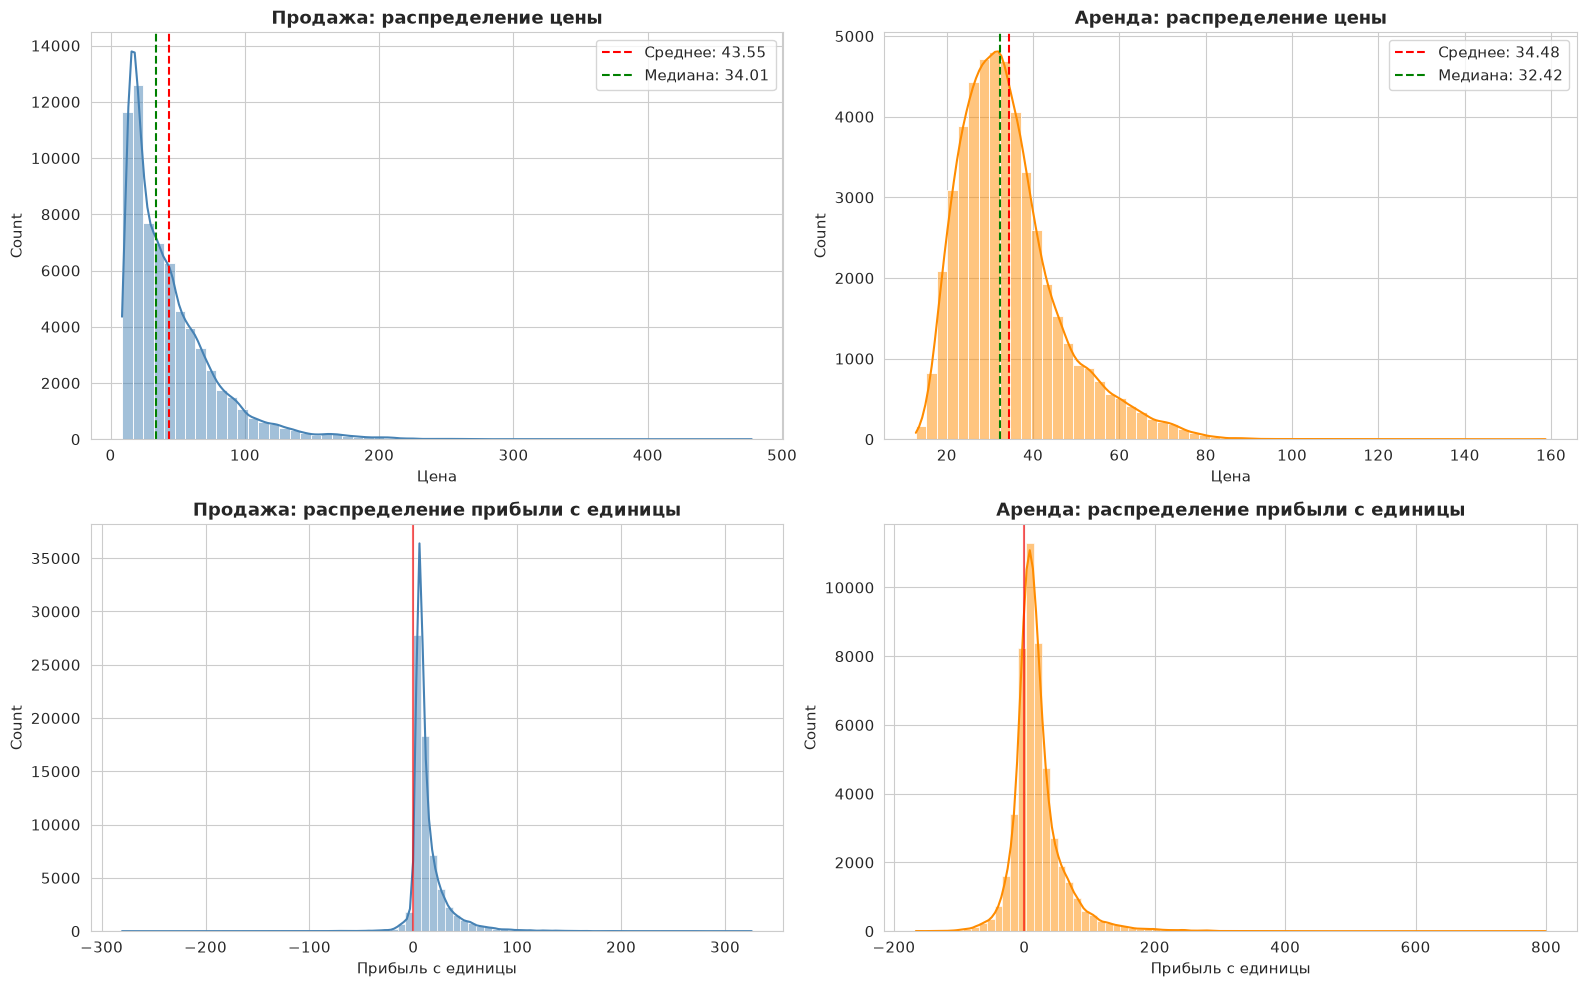

In [320]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

sns.histplot(df_sale['price'], bins=60, kde=True, ax=axes[0, 0], color='steelblue')
axes[0, 0].axvline(df_sale['price'].mean(), color='red', ls='--',
                   label=f"Среднее: {df_sale['price'].mean():.2f}")
axes[0, 0].axvline(df_sale['price'].median(), color='green', ls='--',
                   label=f"Медиана: {df_sale['price'].median():.2f}")
axes[0, 0].set_title('Продажа: распределение цены')
axes[0, 0].set_xlabel('Цена')
axes[0, 0].legend()

sns.histplot(df_rent['price'], bins=60, kde=True, ax=axes[0, 1], color='darkorange')
axes[0, 1].axvline(df_rent['price'].mean(), color='red', ls='--',
                   label=f"Среднее: {df_rent['price'].mean():.2f}")
axes[0, 1].axvline(df_rent['price'].median(), color='green', ls='--',
                   label=f"Медиана: {df_rent['price'].median():.2f}")
axes[0, 1].set_title('Аренда: распределение цены')
axes[0, 1].set_xlabel('Цена')
axes[0, 1].legend()


sns.histplot(df_sale['profit_per_item'], bins=80, kde=True, ax=axes[1, 0], color='steelblue')
axes[1, 0].axvline(0, color='red', ls='-', alpha=0.6)
axes[1, 0].set_title('Продажа: распределение прибыли с единицы')
axes[1, 0].set_xlabel('Прибыль с единицы')

sns.histplot(df_rent['profit_per_item'], bins=80, kde=True, ax=axes[1, 1], color='darkorange')
axes[1, 1].axvline(0, color='red', ls='-', alpha=0.6)
axes[1, 1].set_title('Аренда: распределение прибыли с единицы')
axes[1, 1].set_xlabel('Прибыль с единицы')

plt.tight_layout()
plt.show()

### Наблюдение:

**Графики наглядно демонстрируют:**  
Основной диапазон цен **продажного сегмента** сосредоточен в пределах 0 и равномерно падает до 100 (то есть количественно преобладает торговля более дешёвыми позициями), однако пристутсвуют большие выбросы (очень дорогие позиции), тянущие среднее вправо от медианы. Прибыль аналогично преимущественно сосредоточена близ ~20. 

В свою очередь в **аренде** ценовой сегмент менее подвержен выбросам и нормально распределён в окрестности медианы (близкой к среднему). А вот прибыль имеет большие хвосты с большим доходом.

### Boxplot-сравнение

Boxplot-ы позволяют наглядно сравнить медианы, квартили и выбросы между сегментами.  
Красная линия — нулевая прибыль.

/tmp/ipykernel_41987/1770513196.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='is_rental', y='price', ax=axes[0], palette='Set2')
/tmp/ipykernel_41987/1770513196.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Продажа', 'Аренда'])
/tmp/ipykernel_41987/1770513196.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='is_rental', y='profit_per_item', ax=axes[1], palette='Set2')
/tmp/ipykernel_41987/1770513196.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or

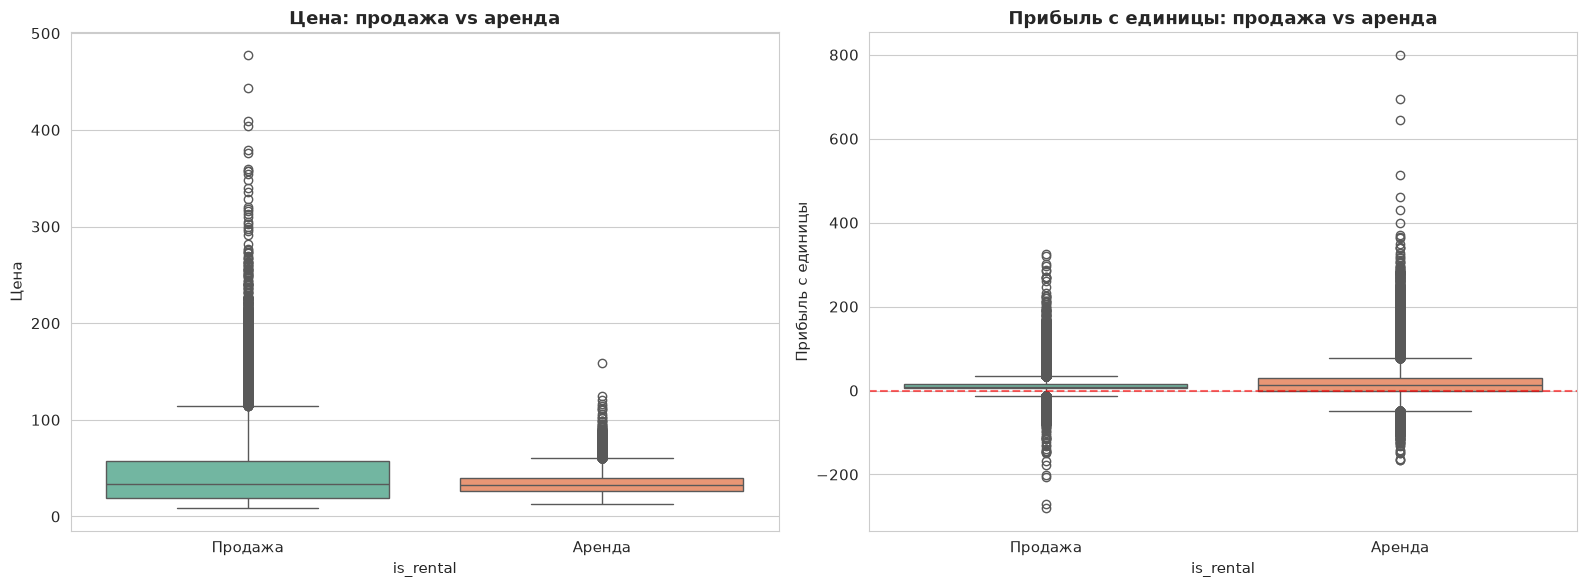

In [321]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(data=df, x='is_rental', y='price', ax=axes[0], palette='Set2')
axes[0].set_xticklabels(['Продажа', 'Аренда'])
axes[0].set_title('Цена: продажа vs аренда')
axes[0].set_ylabel('Цена')

sns.boxplot(data=df, x='is_rental', y='profit_per_item', ax=axes[1], palette='Set2')
axes[1].set_xticklabels(['Продажа', 'Аренда'])
axes[1].set_title('Прибыль с единицы: продажа vs аренда')
axes[1].set_ylabel('Прибыль с единицы')
axes[1].axhline(0, color='red', ls='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Налюдение
Box-plot сравнение подтверждает предыдущие выводы из гистограмм.

## 5. Временной анализ

Анализируем динамику продаж и аренды на разных горизонтах:

- общая картина (MA7),
- по месяцам,
- по дням недели.

Цель: выявить тренд, визуальные аномалии и оценить, синхронизированы ли сегменты во времени. Годовая сезонность недоступна (в данных 1 год), недельная проверяется отдельно по дням недели.

### Динамика прибыли: общая картина

Ниже — динамика прибыли по дням с разделением на продажу и аренду.  
Красная линия — общая прибыль, синяя и оранжевая — вклады сегментов.

In [322]:
def daily_agg(data):
    return data.groupby('date_confirm').agg(
        revenue=('revenue', 'sum'),
        profit=('profit', 'sum'),
        orders=('order_id', 'nunique'),
        rows=('order_id', 'count'),
    ).reset_index()

In [323]:
daily_all  = daily_agg(df)
daily_sale = daily_agg(df_sale)
daily_rent = daily_agg(df_rent)

In [324]:
daily_all = daily_all.merge(
    daily_sale[['date_confirm', 'profit']].rename(columns={'profit': 'profit_sale'}),
    on='date_confirm', how='left'
).merge(
    daily_rent[['date_confirm', 'profit']].rename(columns={'profit': 'profit_rent'}),
    on='date_confirm', how='left'
).fillna(0)

display(daily_all.head())

,date_confirm,revenue,profit,orders,rows,profit_sale,profit_rent
0,2023-08-01,"17,451.80","7,977.34",349,410,"3,805.22","4,172.12"
1,2023-08-02,"18,129.88","7,894.23",334,399,"4,148.44","3,745.79"
2,2023-08-03,"16,491.91","6,984.33",329,398,"3,581.16","3,403.17"
3,2023-08-04,"16,003.29","6,987.63",300,364,"3,528.80","3,458.83"
4,2023-08-05,"10,794.50","4,891.38",206,246,"2,183.25","2,708.13"


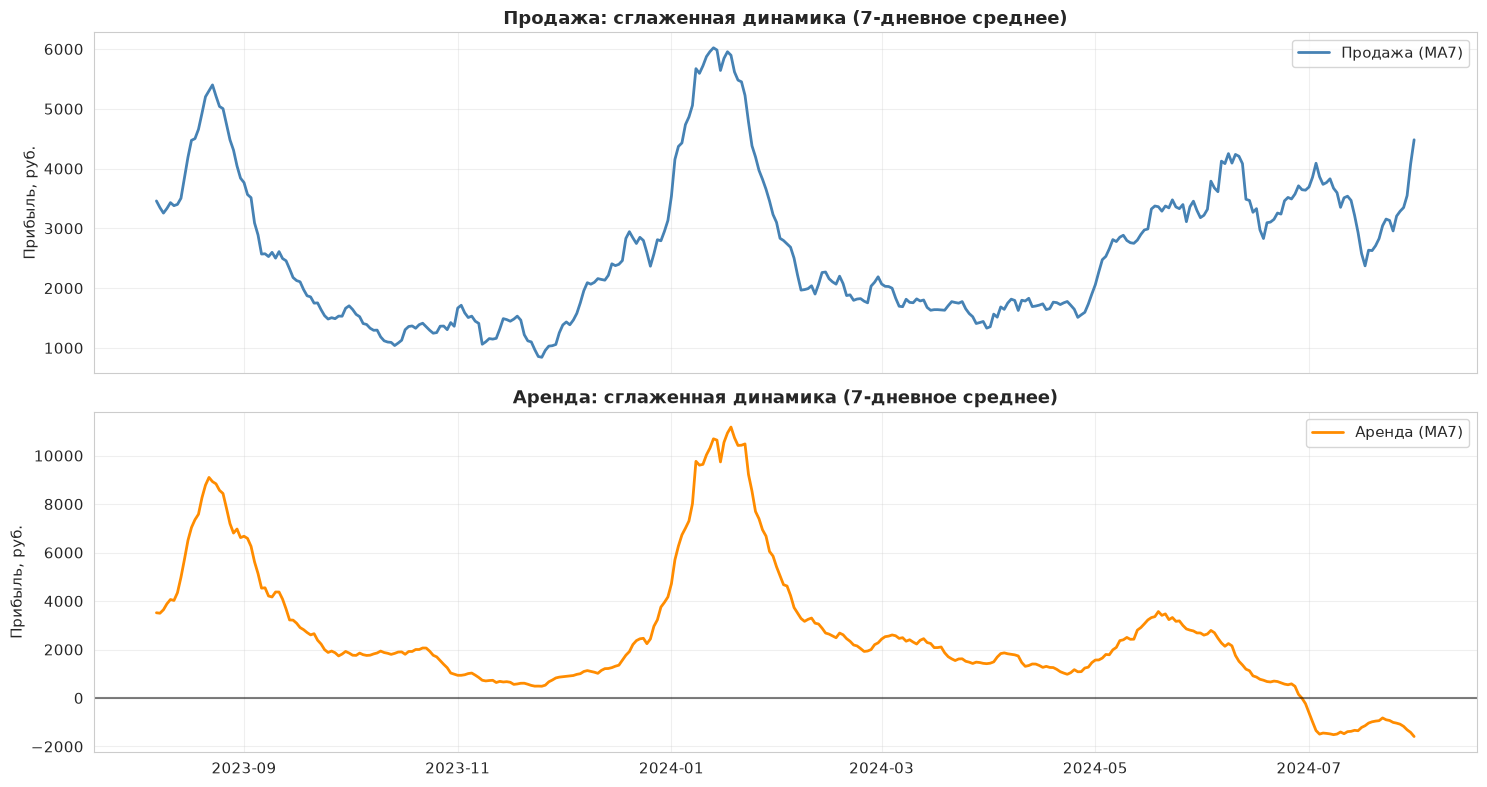

In [325]:
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)

sm_sale = daily_sale.set_index('date_confirm')['profit'].rolling(7).mean()
sm_rent = daily_rent.set_index('date_confirm')['profit'].rolling(7).mean()

axes[0].plot(sm_sale.index, sm_sale.values, color='steelblue', lw=2,
             label='Продажа (MA7)')
axes[0].set_ylabel('Прибыль, руб.')
axes[0].set_title('Продажа: сглаженная динамика (7-дневное среднее)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(sm_rent.index, sm_rent.values, color='darkorange', lw=2,
             label='Аренда (MA7)')
axes[1].axhline(0, color='black', ls='-', alpha=0.5)
axes[1].set_ylabel('Прибыль, руб.')
axes[1].set_title('Аренда: сглаженная динамика (7-дневное среднее)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Наблюдение

В обоих бизнес-сегментах обнаружены одновременные всплески (в районе августа и января). О годовой сезонности говрить возможности нет ввиду ограничения горизонта данных в один год.  
Также наблюдается **аномальный** провал аренды в последний месяц.

### Помесячная динамика

Агрегация по месяцам даёт более чистую картину и позволяет оценить сезонность.

In [326]:
def monthly_agg(data):
    return data.set_index('date_confirm').resample('ME').agg(
        revenue=('revenue', 'sum'),
        profit=('profit', 'sum'),
        orders=('order_id', 'nunique'),
    ).reset_index()

In [327]:
monthly_all  = monthly_agg(df)
monthly_sale = monthly_agg(df_sale)
monthly_rent = monthly_agg(df_rent)

In [328]:
monthly = monthly_all.rename(columns={'revenue': 'revenue_total', 'profit': 'profit_total'})

monthly = monthly.merge(
    monthly_sale[['date_confirm', 'revenue', 'profit']].rename(
        columns={'revenue': 'revenue_sale', 'profit': 'profit_sale'}),
    on='date_confirm', how='left'
).merge(
    monthly_rent[['date_confirm', 'revenue', 'profit']].rename(
        columns={'revenue': 'revenue_rent', 'profit': 'profit_rent'}),
    on='date_confirm', how='left'
).fillna(0)

monthly['month'] = monthly['date_confirm'].dt.strftime('%Y-%m')

In [329]:
display(Markdown("### Помесячная динамика"))
display(monthly[['month', 'revenue_total', 'revenue_sale', 'revenue_rent',
                 'profit_total', 'profit_sale', 'profit_rent']].round(2))

### Помесячная динамика

,month,revenue_total,revenue_sale,revenue_rent,profit_total,profit_sale,profit_rent
0,2023-08,"693,110.45","402,419.48","290,690.97","325,446.38","129,534.00","195,912.38"
1,2023-09,"296,588.35","184,829.08","111,759.27","147,850.87","60,109.84","87,741.03"
2,2023-10,"201,566.83","133,120.74","68,446.09","92,140.75","40,001.52","52,139.23"
3,2023-11,"154,166.69","129,031.95","25,134.74","59,746.76","38,401.07","21,345.69"
4,2023-12,"354,842.81","242,164.89","112,677.92","142,228.64","76,695.87","65,532.77"
5,2024-01,"838,790.79","456,357.08","382,433.71","420,642.64","151,691.07","268,951.57"
6,2024-02,"282,608.62","190,522.83","92,085.79","135,998.97","59,762.03","76,236.94"
7,2024-03,"250,215.47","166,045.84","84,169.63","107,514.08","49,196.23","58,317.85"
8,2024-04,"252,834.20","186,460.55","66,373.65","96,253.65","53,938.61","42,315.04"
9,2024-05,"517,079.64","322,054.47","195,025.17","184,618.53","97,398.02","87,220.51"


### Визуализация помесячной динамики

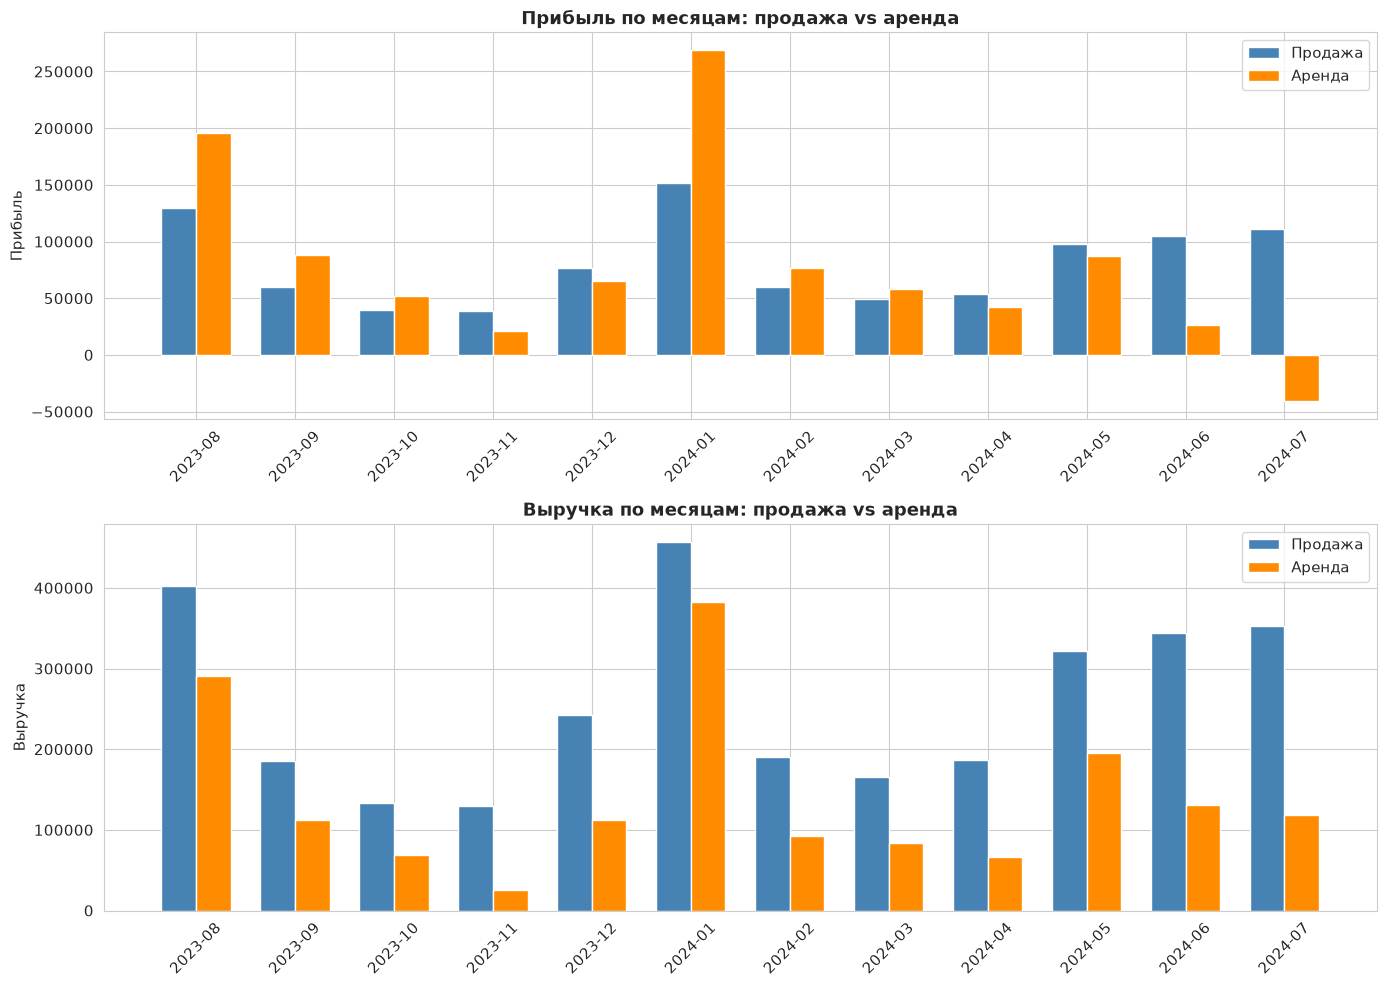

In [330]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

x = np.arange(len(monthly))
width = 0.35

axes[0].bar(x - width/2, monthly['profit_sale'], width, label='Продажа', color='steelblue')
axes[0].bar(x + width/2, monthly['profit_rent'], width, label='Аренда', color='darkorange')
axes[0].set_xticks(x)
axes[0].set_xticklabels(monthly['month'], rotation=45)
axes[0].set_title('Прибыль по месяцам: продажа vs аренда')
axes[0].set_ylabel('Прибыль')
axes[0].legend()

axes[1].bar(x - width/2, monthly['revenue_sale'], width, label='Продажа', color='steelblue')
axes[1].bar(x + width/2, monthly['revenue_rent'], width, label='Аренда', color='darkorange')
axes[1].set_xticks(x)
axes[1].set_xticklabels(monthly['month'], rotation=45)
axes[1].set_title('Выручка по месяцам: продажа vs аренда')
axes[1].set_ylabel('Выручка')
axes[1].legend()

plt.tight_layout()
plt.show()

### Наблюдение

Данные гистограммы подтверждают предыдущие суждения.

### Дни недели

Проверяем, есть ли паттерн по дням недели — обычно в e-commerce пик приходится на выходные.

In [331]:
dow = df.copy()
dow['dow'] = dow['date_confirm'].dt.dayofweek  
dow_names = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']

In [332]:
dow_sale = dow[dow['is_rental'] == 0].groupby('dow')['profit'].mean()
dow_rent = dow[dow['is_rental'] == 1].groupby('dow')['profit'].mean()

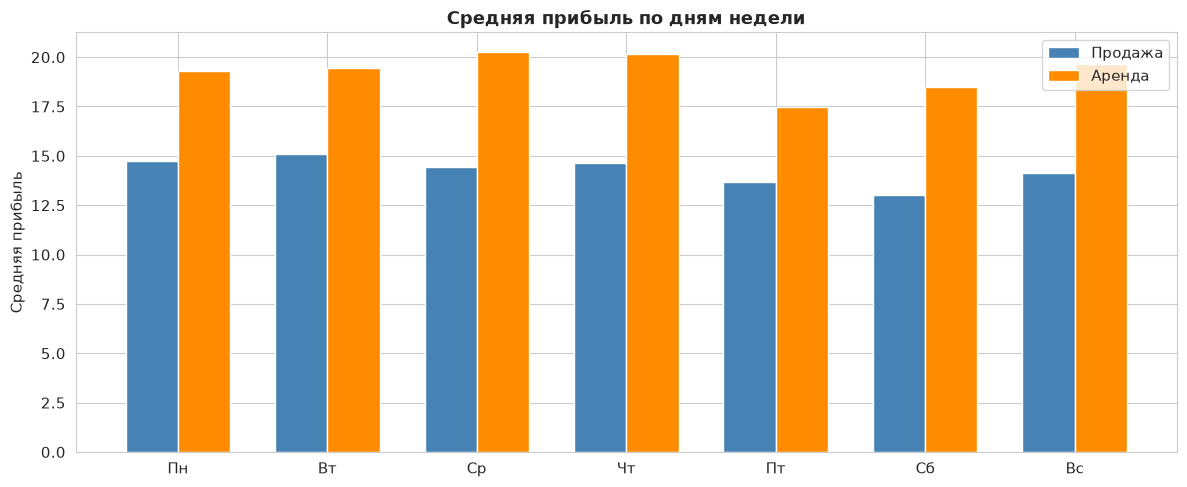

In [333]:
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(7)
width = 0.35
ax.bar(x - width/2, dow_sale.values, width, label='Продажа', color='steelblue')
ax.bar(x + width/2, dow_rent.values, width, label='Аренда', color='darkorange')
ax.set_xticks(x)
ax.set_xticklabels(dow_names)
ax.set_title('Средняя прибыль по дням недели')
ax.set_ylabel('Средняя прибыль')
ax.legend()
plt.tight_layout()
plt.show()

### Наблюдение

Статистически значимой разницы между днями недели не обнаружено.

### Динамика аренды по месяцам: поиск точки перелома

Смотрим ключевые метрики аренды месяц за месяцем:
- **Доля убыточных строк** — растёт ли доля проблемных заказов.
- **Медиана и средняя прибыль** — устойчива ли экономика сегмента.
- **Доля `Shipped`** — растёт ли доля активных (не завершённых) аренд.
- **Медианная цена** — меняется ли структура заказов.

Точка перелома — месяц, после которого все метрики синхронно ухудшаются.

In [334]:
rent_monthly = df_rent.copy()
rent_monthly['month'] = rent_monthly['date_confirm'].dt.to_period('M').astype(str)

In [335]:
rent_monthly_stats = rent_monthly.groupby('month').agg(
    Строк=('order_id', 'count'),
    Уникальных_заказов=('order_id', 'nunique'),
    Медианная_цена=('price', 'median'),
    Медианная_прибыль_ед=('profit_per_item', 'median'),
    Средняя_прибыль_ед=('profit_per_item', 'mean'),
    Суммарная_прибыль=('profit', 'sum'),
    Доля_убыточных_pct=('profit', lambda x: (x < 0).mean() * 100),
    Доля_Shipped_pct=('status', lambda x: (x == 'Shipped').mean() * 100),
).round(2)

In [336]:
def highlight_bad(val):
    if isinstance(val, (int, float)):
        if val > 50:
            return 'background-color: #ffcccc'
    return ''

In [337]:
display(Markdown("### Помесячная динамика аренды"))
display(
    rent_monthly_stats.style
    .background_gradient(subset=['Доля_убыточных_pct'], cmap='Reds', vmin=0, vmax=80)
    .background_gradient(subset=['Медианная_прибыль_ед'], cmap='RdYlGn', vmin=-15, vmax=25)
    .format({
        'Медианная_цена': '{:.2f}',
        'Медианная_прибыль_ед': '{:.2f}',
        'Средняя_прибыль_ед': '{:.2f}',
        'Суммарная_прибыль': '{:,.0f}',
        'Доля_убыточных_pct': '{:.1f}',
        'Доля_Shipped_pct': '{:.1f}',
    })
)

### Помесячная динамика аренды

,Строк,Уникальных_заказов,Медианная_цена,Медианная_прибыль_ед,Средняя_прибыль_ед,Суммарная_прибыль,Доля_убыточных_pct,Доля_Shipped_pct
month,,,,,,,,
2023-08,7777,6987,34.87,18.19,25.19,"195,912",17.5,18.6
2023-09,3195,3025,33.28,18.46,27.46,"87,741",20.1,26.6
2023-10,2128,2008,30.82,15.70,24.50,"52,139",19.6,23.4
2023-11,777,714,30.48,18.21,27.47,"21,346",21.4,29.1
2023-12,2876,2378,36.20,15.81,22.79,"65,533",18.6,15.5
2024-01,10103,9332,35.63,17.42,26.62,"268,952",18.8,20.6
2024-02,2755,2590,31.68,16.23,27.67,"76,237",20.9,27.4
2024-03,2703,2514,29.35,13.12,21.58,"58,318",23.5,22.9
2024-04,2111,1904,29.90,13.34,20.05,"42,315",23.5,30.2


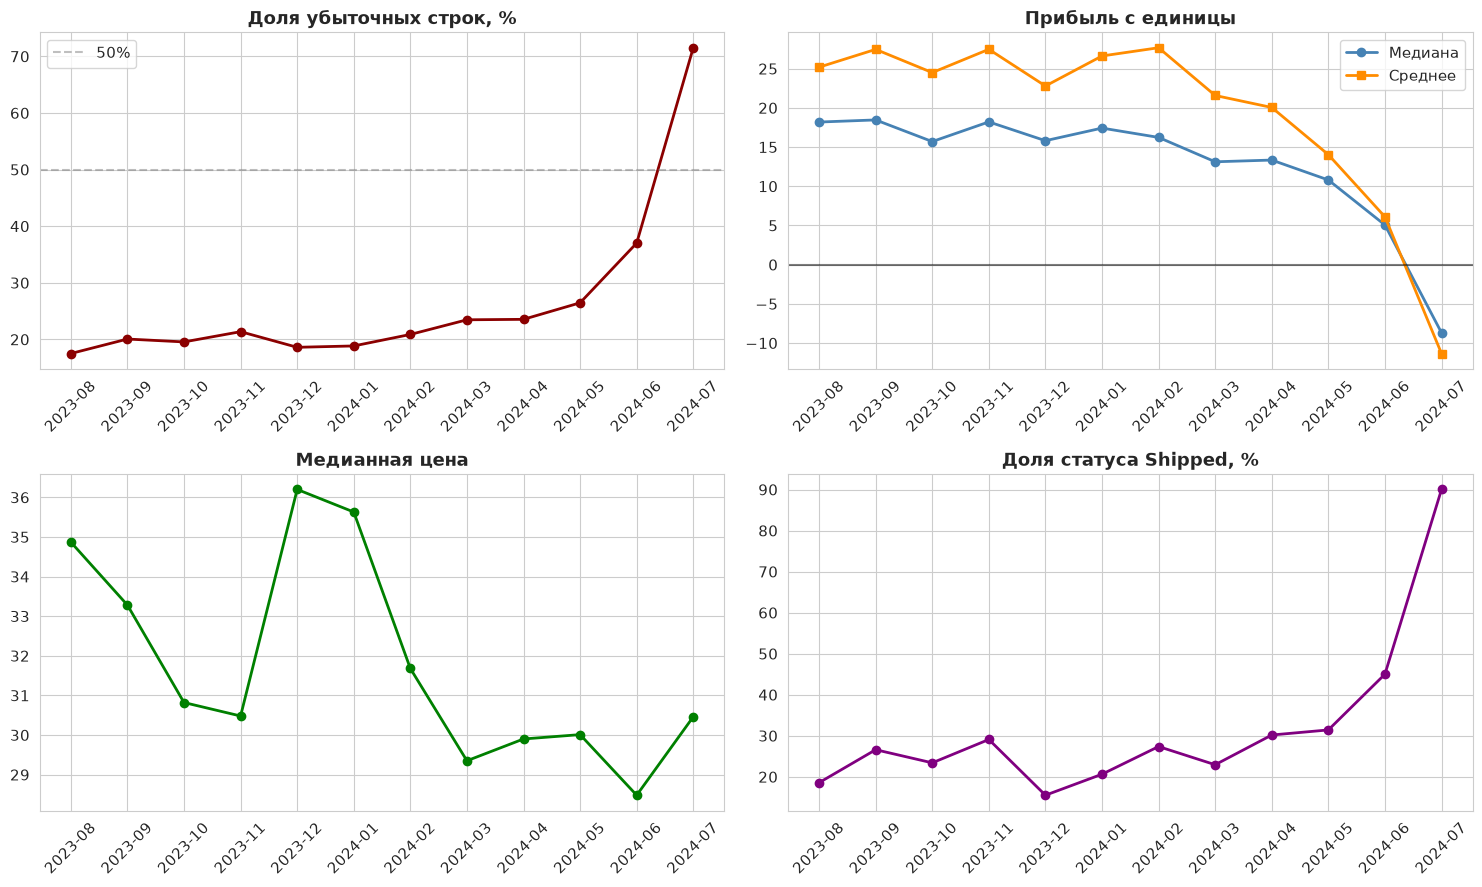

In [338]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

months = rent_monthly_stats.index

axes[0, 0].plot(months, rent_monthly_stats['Доля_убыточных_pct'],
                marker='o', color='darkred', lw=2)
axes[0, 0].axhline(50, color='gray', ls='--', alpha=0.5, label='50%')
axes[0, 0].set_title('Доля убыточных строк, %')
axes[0, 0].tick_params(axis='x', rotation=45)
axes[0, 0].legend()

axes[0, 1].plot(months, rent_monthly_stats['Медианная_прибыль_ед'],
                marker='o', color='steelblue', lw=2, label='Медиана')
axes[0, 1].plot(months, rent_monthly_stats['Средняя_прибыль_ед'],
                marker='s', color='darkorange', lw=2, label='Среднее')
axes[0, 1].axhline(0, color='black', ls='-', alpha=0.5)
axes[0, 1].set_title('Прибыль с единицы')
axes[0, 1].tick_params(axis='x', rotation=45)
axes[0, 1].legend()

axes[1, 0].plot(months, rent_monthly_stats['Медианная_цена'],
                marker='o', color='green', lw=2)
axes[1, 0].set_title('Медианная цена')
axes[1, 0].tick_params(axis='x', rotation=45)

axes[1, 1].plot(months, rent_monthly_stats['Доля_Shipped_pct'],
                marker='o', color='purple', lw=2)
axes[1, 1].set_title('Доля статуса Shipped, %')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### Наблюдение

Начиная с апреля-мая виден **стремительный рост убытков, падение прибыли с единицы**, а также **рост статуса Shipped**, то есть незавершённых аренд.

## Проверим несколько гипотез:

### Разбивка убытков по ценовым сегментам (H1)

Проверяем гипотезу: убытки концентрируются в дешёвом сегменте? (Такой вывод можно сделать из падения медианной цены)  
Разбиваем все аренды на 5 квинтилей по цене и считаем долю убыточных в каждом.

In [339]:
df_rent['price_quintile'] = pd.qcut(
    df_rent['price'], q=5, labels=['Q1 (дешёвые)', 'Q2', 'Q3', 'Q4', 'Q5 (дорогие)']
)

In [340]:
quintile_stats = df_rent.groupby('price_quintile', observed=True).agg(
    Строк=('order_id', 'count'),
    Диапазон_цен=('price', lambda x: f"[{x.min():.0f}–{x.max():.0f}]"),
    Медианная_прибыль_ед=('profit_per_item', 'median'),
    Суммарная_прибыль=('profit', 'sum'),
    Доля_убыточных_pct=('profit', lambda x: (x < 0).mean() * 100),
).round(2)

In [341]:
display(quintile_stats)

,Строк,Диапазон_цен,Медианная_прибыль_ед,Суммарная_прибыль,Доля_убыточных_pct
price_quintile,,,,,
Q1 (дешёвые),9737,[13–25],6.00,"100,358.60",30.74
Q2,9728,[25–30],9.52,"137,011.17",26.42
Q3,9742,[30–35],13.43,"172,607.84",24.76
Q4,9717,[35–42],17.16,"212,869.82",24.46
Q5 (дорогие),9724,[42–159],26.38,"318,661.17",22.95


In [342]:
pivot_loss = df_rent.pivot_table(
    values='profit',
    index='price_quintile',
    columns=df_rent['date_confirm'].dt.to_period('M').astype(str),
    aggfunc=lambda x: (x < 0).mean() * 100,
    observed=True
).round(1)

In [343]:
display(Markdown("### Доля убыточных по квинтилю × месяц"))
display(pivot_loss.style.background_gradient(cmap='Reds', vmin=0, vmax=100))

### Доля убыточных по квинтилю × месяц

date_confirm,2023-08,2023-09,2023-10,2023-11,2023-12,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07
price_quintile,,,,,,,,,,,,
Q1 (дешёвые),24.500000,28.600000,24.200000,27.000000,20.400000,24.000000,26.400000,27.700000,24.600000,24.900000,34.300000,68.900000
Q2,16.900000,19.900000,19.100000,23.800000,19.100000,19.500000,20.700000,23.000000,23.000000,24.400000,36.900000,68.200000
Q3,14.700000,18.300000,18.800000,18.200000,14.900000,18.900000,21.000000,23.100000,21.200000,27.400000,37.500000,75.500000
Q4,15.300000,16.800000,16.800000,10.800000,19.400000,17.900000,19.200000,21.300000,23.300000,29.000000,42.100000,77.100000
Q5 (дорогие),18.200000,18.100000,16.700000,23.300000,19.300000,17.100000,16.400000,18.300000,26.800000,28.600000,37.300000,70.200000


**Вывод по H1.** На базовом уровне доля убыточных слабо зависит от цены: в Q1 (дешёвые) 30.7%, в Q5 (дорогие) 23.0%. Разрыв небольшой, гипотеза о концентрации убытков в дешёвом сегменте подтверждается лишь частично. В июле 2024 все квинтили сближаются в районе 70% — то есть июльский всплеск не связан с ценовой структурой и требует другого объяснения.

### Разбивка по статусам (H2)

Проверяем: убытки идут через `Shipped` (активные аренды) или через `Returned`
(завершённые)? Если убыточные `Shipped` растут — значит текущие аренды
не покрывают свои расходы. 

In [344]:
status_month_stats = df_rent.groupby([
    df_rent['date_confirm'].dt.to_period('M').astype(str), 'status'
]).agg(
    Строк=('order_id', 'count'),
    Суммарная_прибыль=('profit', 'sum'),
    Медианная_прибыль_ед=('profit_per_item', 'median'),
    Доля_убыточных_pct=('profit', lambda x: (x < 0).mean() * 100),
).round(2)

In [345]:
display(Markdown("### Аренда: метрики по статусам × месяц"))
display(status_month_stats)

pivot_status_loss = df_rent.pivot_table(
    values='profit',
    index=df_rent['date_confirm'].dt.to_period('M').astype(str),
    columns='status',
    aggfunc=lambda x: (x < 0).mean() * 100,
).round(1)

### Аренда: метрики по статусам × месяц

Строк  Суммарная_прибыль  Медианная_прибыль_ед  Доля_убыточных_pct
date_confirm status                                                                      
2023-08      Returned   6333         112,120.72                 15.42               17.32
             Shipped    1444          83,791.66                 59.08               18.28
2023-09      Returned   2345          37,263.25                 14.43               20.04
             Shipped     850          50,477.78                 60.00               20.12
2023-10      Returned   1630          23,335.21                 12.02               19.69
             Shipped     498          28,804.02                 58.64               19.08
2023-11      Returned    551           8,025.93                 11.41               23.23
             Shipped     226          13,319.76                 55.86               16.81
2023-12      Returned   2430          40,750.04                 14.04               17.78
             Shipped     446          24,782.73                 57.24               23.09
2024-01      Returned   8019         132,271.37                 13.92               19.85
             Shipped    2084         136,680.20                 64.78               14.92
2024-02      Returned   2001          30,439.96                 11.85               22.29
             Shipped     754          45,796.98                 61.20               17.11
2024-03      Returned   2083          27,731.03                 10.44               23.14
             Shipped     620          30,586.82                 50.29               24.52
2024-04      Returned   1474          22,167.73                 12.16               19.67
             Shipped     637          20,147.31                 27.86               32.50
2024-05      Returned   4263          55,390.92                 11.79               19.94
             Shipped    1953          31,829.59                  6.39               40.71
2024-06      Returned   2415          24,168.10                  8.37               24.72
             Shipped    1976           2,633.75                 -1.14               52.02
2024-07      Returned    361           1,600.92                  2.82               39.34
             Shipped    3255         -42,607.18                -10.46               75.08

In [346]:
display(Markdown("### Доля убыточных по статусу × месяц, %"))
display(pivot_status_loss.style.background_gradient(cmap='Reds', vmin=0, vmax=100))

### Доля убыточных по статусу × месяц, %

status,Returned,Shipped
date_confirm,,
2023-08,17.300000,18.300000
2023-09,20.000000,20.100000
2023-10,19.700000,19.100000
2023-11,23.200000,16.800000
2023-12,17.800000,23.100000
2024-01,19.900000,14.900000
2024-02,22.300000,17.100000
2024-03,23.100000,24.500000
2024-04,19.700000,32.500000


**Вывод по H2.** Всплеск убытков в июне-июле идёт через строки со статусом `Shipped`: в июле их доля убыточных — 75%, при том что их доля в общем объёме аренд выросла до 90%.

**Важная оговорка.** `profit` по строкам `Shipped` — не финальный. Это промежуточное начисление, а не итоговый результат аренды. Сравнивать величину profit между `Shipped` и `Returned` некорректно. Корректно сравнивать только долю и динамику.

### Проверка: убытки — это выбросы или системная проблема? (H3)

Если суммарный убыток создают 5–10 крупных позиций — это артефакт.
Если убытки распределены по сотням мелких позиций — это системная проблема.

In [347]:
july_rent = df_rent[df_rent['date_confirm'].dt.to_period('M').astype(str) == '2024-07']
july_loss = july_rent[july_rent['profit'] < 0].sort_values('profit')

In [348]:
display(Markdown("### Июль 2024: топ-10 убыточных позиций"))
display(july_loss.nsmallest(10, 'profit')[
    ['order_id', 'price', 'profit_per_item', 'profit', 'status']
].reset_index(drop=True))

### Июль 2024: топ-10 убыточных позиций

,order_id,price,profit_per_item,profit,status
0,1488877,73.21,-114.34,-114.34,Shipped
1,1454685,48.33,-110.24,-110.24,Shipped
2,1544809,59.92,-107.46,-107.46,Shipped
3,1530223,41.87,-107.02,-107.02,Shipped
4,1514412,82.17,-105.88,-105.88,Shipped
5,1566941,50.65,-105.62,-105.62,Shipped
6,1540962,66.74,-103.41,-103.41,Shipped
7,1440319,48.29,-101.75,-101.75,Shipped
8,1475927,41.55,-99.77,-99.77,Shipped
9,1510971,56.51,-96.76,-96.76,Shipped


In [349]:
loss_sorted = july_loss['profit'].values
cumulative_share = np.cumsum(loss_sorted) / loss_sorted.sum() * 100

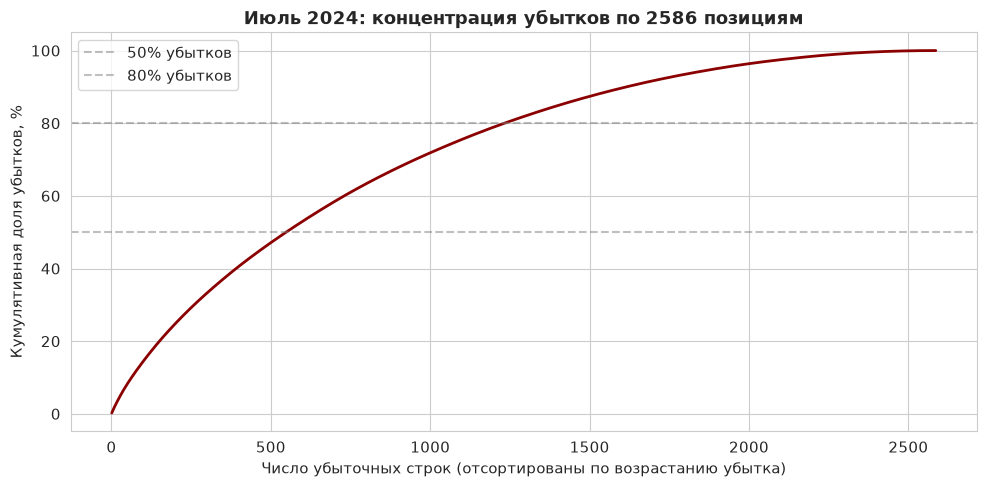

In [350]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(np.arange(1, len(loss_sorted) + 1), cumulative_share,
        color='darkred', lw=2)
ax.axhline(50, color='gray', ls='--', alpha=0.5, label='50% убытков')
ax.axhline(80, color='gray', ls='--', alpha=0.5, label='80% убытков')
ax.set_xlabel('Число убыточных строк (отсортированы по возрастанию убытка)')
ax.set_ylabel('Кумулятивная доля убытков, %')
ax.set_title(f'Июль 2024: концентрация убытков по {len(loss_sorted)} позициям')
ax.legend()
plt.tight_layout()
plt.show()

In [351]:
n_50 = (cumulative_share <= 50).sum() + 1
n_80 = (cumulative_share <= 80).sum() + 1
total = len(loss_sorted)

display(Markdown(
    f"**Всего убыточных строк в июле:** {total}\n\n"
    f"- **50% убытков** концентрируется в **{n_50} строках** "
    f"({n_50 / total * 100:.1f}% от общего числа убыточных)\n"
    f"- **80% убытков** концентрируется в **{n_80} строках** "
    f"({n_80 / total * 100:.1f}% от общего числа убыточных)"
))

**Всего убыточных строк в июле:** 2586

- **50% убытков** концентрируется в **548 строках** (21.2% от общего числа убыточных)
- **80% убытков** концентрируется в **1233 строках** (47.7% от общего числа убыточных)

**Вывод по H3.** Убытки распределены умеренно концентрированно: 50% суммарного убытка приходятся на 21% убыточных строк, 80% — на 48%. Это не единичные выбросы и не полностью равномерное распределение — отдельного «десятка виновных сделок» нет.

При этом топ-10 убытков июля **все** имеют статус `Shipped`. Это прямое указание на то, что крупнейшие убытки месяца — артефакт незавершённых аренд, а не бизнес-событие.

### Проверка аренды только на завершённых сделках

In [352]:
rent_completed = df_rent[df_rent['status'] == 'Returned'].copy()
rent_completed['month'] = rent_completed['date_confirm'].dt.to_period('M').astype(str)

completed_stats = rent_completed.groupby('month').agg(
    Строк=('order_id', 'count'),
    Медианная_прибыль_ед=('profit_per_item', 'median'),
    Средняя_прибыль_ед=('profit_per_item', 'mean'),
    Суммарная_прибыль=('profit', 'sum'),
    Доля_убыточных_pct=('profit', lambda x: (x < 0).mean() * 100),
).round(2)

display(Markdown("### Аренда: только завершённые сделки (status = Returned)"))
display(completed_stats.style.background_gradient(
    subset=['Доля_убыточных_pct'], cmap='Reds', vmin=0, vmax=50))

# --- Сравнение: все аренды vs только завершённые ---
compare_rent = pd.DataFrame({
    'Все аренды': rent_monthly_stats['Доля_убыточных_pct'],
    'Только Returned': completed_stats['Доля_убыточных_pct'],
}).round(1)

display(Markdown("### Сравнение: доля убыточных, %"))
display(compare_rent)

### Аренда: только завершённые сделки (status = Returned)

,Строк,Медианная_прибыль_ед,Средняя_прибыль_ед,Суммарная_прибыль,Доля_убыточных_pct
month,,,,,
2023-08,6333,15.420000,17.700000,112120.720000,17.320000
2023-09,2345,14.430000,15.890000,37263.250000,20.040000
2023-10,1630,12.020000,14.320000,23335.210000,19.690000
2023-11,551,11.410000,14.570000,8025.930000,23.230000
2023-12,2430,14.040000,16.770000,40750.040000,17.780000
2024-01,8019,13.920000,16.490000,132271.370000,19.850000
2024-02,2001,11.850000,15.210000,30439.960000,22.290000
2024-03,2083,10.440000,13.310000,27731.030000,23.140000
2024-04,1474,12.160000,15.040000,22167.730000,19.670000


### Сравнение: доля убыточных, %

,Все аренды,Только Returned
month,,
2023-08,17.50,17.30
2023-09,20.10,20.00
2023-10,19.60,19.70
2023-11,21.40,23.20
2023-12,18.60,17.80
2024-01,18.80,19.80
2024-02,20.90,22.30
2024-03,23.50,23.10
2024-04,23.50,19.70


In [353]:
completion_rate = pd.DataFrame({
    'Всего': rent_monthly_stats['Строк'],
    'Returned': completed_stats['Строк'],
}).fillna(0)
completion_rate['Доля завершённых, %'] = (
    completion_rate['Returned'] / completion_rate['Всего'] * 100
).round(1)

display(Markdown("### Доля завершённых аренд по месяцам"))
display(completion_rate)

compare_final = pd.DataFrame({
    'Все аренды, медиана': rent_monthly_stats['Медианная_прибыль_ед'],
    'Returned, медиана': completed_stats['Медианная_прибыль_ед'],
}).fillna(0).round(2)

display(Markdown("### Медианная прибыль: все аренды vs завершённые"))
display(compare_final)

### Доля завершённых аренд по месяцам

,Всего,Returned,"Доля завершённых, %"
month,,,
2023-08,7777,6333,81.40
2023-09,3195,2345,73.40
2023-10,2128,1630,76.60
2023-11,777,551,70.90
2023-12,2876,2430,84.50
2024-01,10103,8019,79.40
2024-02,2755,2001,72.60
2024-03,2703,2083,77.10
2024-04,2111,1474,69.80


### Медианная прибыль: все аренды vs завершённые

,"Все аренды, медиана","Returned, медиана"
month,,
2023-08,18.19,15.42
2023-09,18.46,14.43
2023-10,15.70,12.02
2023-11,18.21,11.41
2023-12,15.81,14.04
2024-01,17.42,13.92
2024-02,16.23,11.85
2024-03,13.12,10.44
2024-04,13.34,12.16


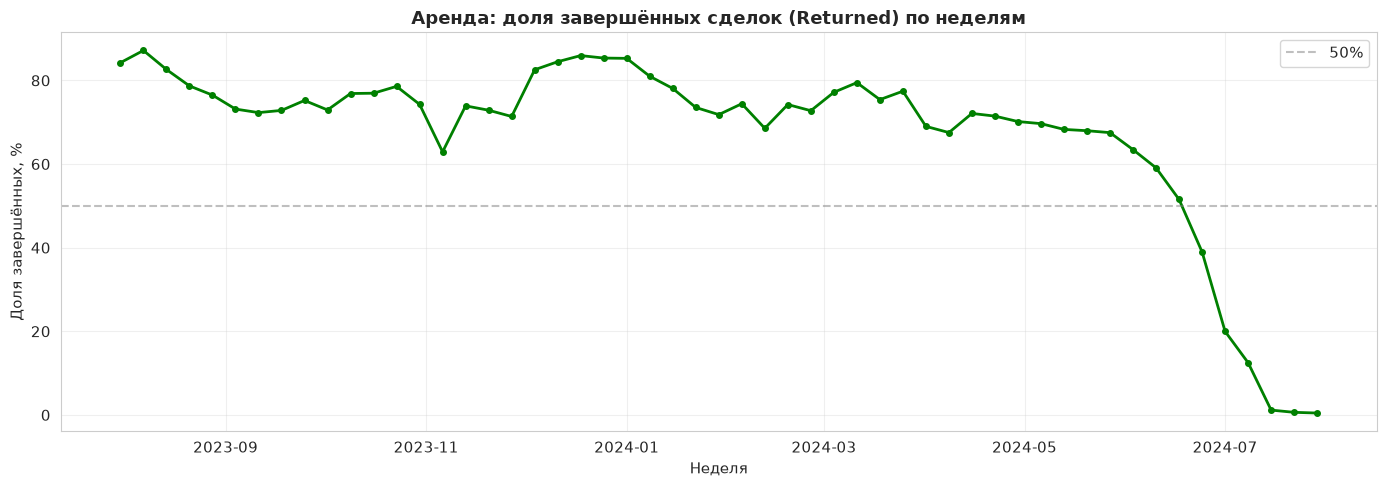

#### Последние 10 недель

,Всего,Returned,Доля_завершённых_pct
week,,,
2024-05-27,1511,1020,67.50
2024-06-03,1425,904,63.40
2024-06-10,875,517,59.10
2024-06-17,819,422,51.50
2024-06-24,1003,391,39.00
2024-07-01,1187,237,20.00
2024-07-08,905,113,12.50
2024-07-15,433,5,1.20
2024-07-22,646,4,0.60


In [354]:
rent_weekly = df_rent.copy()
rent_weekly['week'] = rent_weekly['date_confirm'].dt.to_period('W').dt.start_time

completion_weekly = rent_weekly.groupby('week').agg(
    Всего=('order_id', 'count'),
    Returned=('status', lambda x: (x == 'Returned').sum()),
)
completion_weekly['Доля_завершённых_pct'] = (
    completion_weekly['Returned'] / completion_weekly['Всего'] * 100
)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(completion_weekly.index, completion_weekly['Доля_завершённых_pct'],
        marker='o', ms=4, lw=2, color='green')
ax.axhline(50, color='gray', ls='--', alpha=0.5, label='50%')
ax.set_title('Аренда: доля завершённых сделок (Returned) по неделям')
ax.set_ylabel('Доля завершённых, %')
ax.set_xlabel('Неделя')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(Markdown("#### Последние 10 недель"))
display(completion_weekly.tail(10).round(1))

### Артефакт среза данных в июле 2024

В июле 2024 суммарная прибыль аренды отрицательна (−41 000 ). При детальном разборе выясняется, что это следствие среза данных, а не бизнес-провала:

- **90% июльских аренд** находятся в статусе `Shipped` — они ещё не завершены.
- Для незавершённых аренд `profit` начисляется частично (негативно) — финальный доход признаётся при переходе в `Returned`.
- Доля `Shipped` выросла с 25% (март) до 90% (июль) **не из-за бизнес-проблемы**, а из-за того, что мы смотрим срез данных, обрезанный на 2024-07-31.

**Реальная картина по завершённым сделкам:**

| Месяц | Returned, медиана | Доля убыточных, % |
|---|---|---|
| 2024-03 | 10.44 | 23.1 |
| 2024-04 | 12.16 | 19.7 |
| 2024-05 | 11.79 | 19.9 |
| 2024-06 | 8.37 | 24.7 |
| 2024-07 | 2.82 | 39.3 |

**Наблюдаемые эффекты неразделимы.** Падение медианы `Returned` с июня может отражать как реальное ухудшение экономики аренды, так и изменение состава завершающихся сделок: в конце периода успевают завершиться только короткие/простые аренды. Данных для разделения этих двух эффектов в датасете нет — отсутствуют длительность аренды и дата старта.

**Итог:** провал в аренде в июне-июле 2024 — следствие среза данных (часть аренд не успела завершиться), а не подтверждённое ухудшение бизнеса.

## 6. Корреляции и анализ заказов

Проверяем:
- корреляции между числовыми признаками внутри каждого сегмента;
- структуру заказов: сколько позиций в среднем в одном заказе;
- средний чек по сегментам.

In [355]:
def plot_corr_clean(data, name, drop_cols=None):
    """Корреляция по осмысленным признакам."""
    base_cols = ['price', 'count', 'profit_per_item', 'revenue', 'profit']
    drop_cols = drop_cols or []
    cols = [c for c in base_cols if c not in drop_cols]

    corr = data[cols].corr()
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
                square=True, ax=ax, cbar_kws={'shrink': .8},
                vmin=-1, vmax=1)
    title = f'{name}: корреляционная матрица'
    if drop_cols:
        title += f' (исключены: {", ".join(drop_cols)})'
    ax.set_title(title)
    plt.tight_layout()
    plt.show()
    return corr

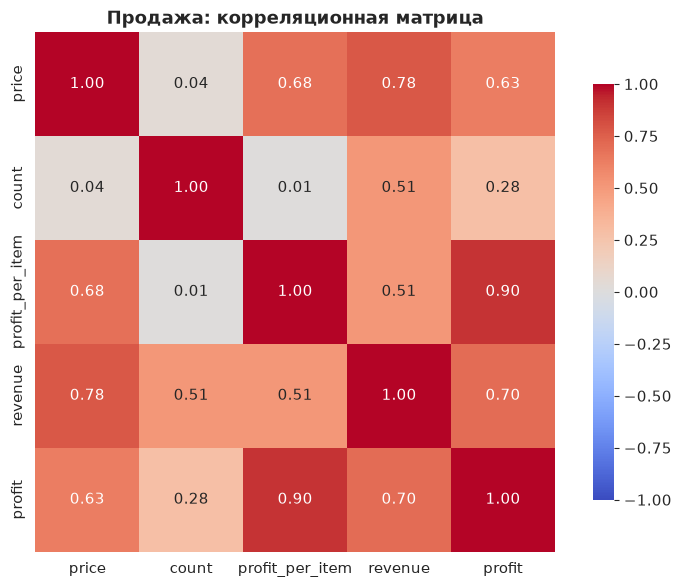

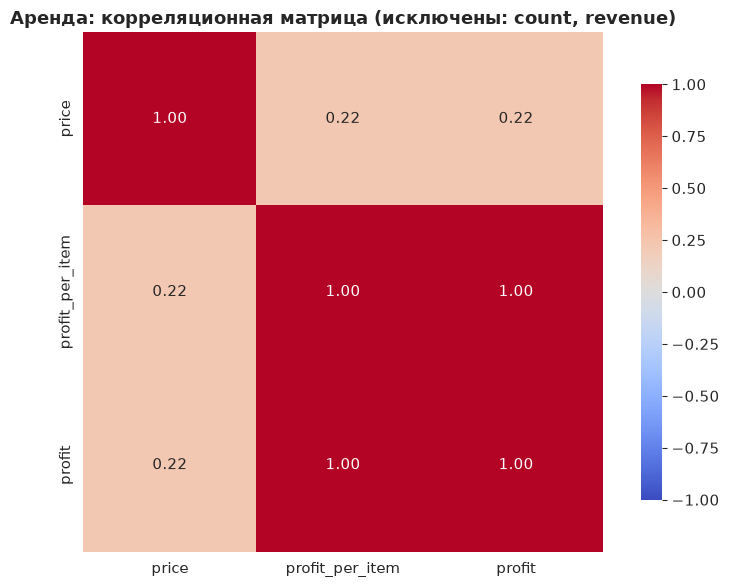

In [356]:
# В аренде count всегда 1, а revenue = price * 1 → дропаем count и revenue
corr_sale = plot_corr_clean(df_sale, 'Продажа')
corr_rent = plot_corr_clean(df_rent, 'Аренда', drop_cols=['count', 'revenue'])

### Наблюдения

- У **продажи** `revenue` и `profit` сильно коррелируют с `price` — чем дороже товар, тем больше выручка.
- У **аренды**: доход зависит не столько от цены предмета, сколько от количества сдач (которое в датасете не отражено).

In [357]:
def order_structure(data, name):
    orders = data.groupby('order_id').agg(
        позиций=('product_id', 'count'),
        revenue=('revenue', 'sum'),
        profit=('profit', 'sum'),
    )
    
    display(Markdown(f"### {name}: структура заказов"))
    display(Markdown(f"- Уникальных заказов: **{len(orders):,}**"))
    display(Markdown(f"- Позиций на заказ (среднее): **{orders['позиций'].mean():.2f}**"))
    display(Markdown(f"- Позиций на заказ (медиана): **{orders['позиций'].median():.0f}**"))
    display(Markdown(f"- Позиций на заказ (макс): **{orders['позиций'].max()}**"))
    display(Markdown(f"- Средний чек: **{orders['revenue'].mean():,.2f}**"))
    display(Markdown(f"- Медианный чек: **{orders['revenue'].median():,.2f}**"))
    
    dist = orders['позиций'].value_counts().sort_index().head(10)
    display(Markdown("#### Распределение по числу позиций (топ-10)"))
    display(dist.to_frame('Заказов'))

In [358]:
order_structure(df_sale, 'Продажа')
order_structure(df_rent, 'Аренда')

### Продажа: структура заказов

- Уникальных заказов: **61,341**

- Позиций на заказ (среднее): **1.10**

- Позиций на заказ (медиана): **1**

- Позиций на заказ (макс): **31**

...

- Позиций на заказ (макс): **5**

- Средний чек: **37.85**

- Медианный чек: **33.63**

#### Распределение по числу позиций (топ-10)

,Заказов
позиций,
1,40799
2,2840
3,573
4,105
5,6


### Наблюдения

1. **Средний чек.** У продажи средний чек выше.
2. **Позиций на заказ.** Медиана ~ 1, значит, большинство заказов однопозиционные.

Эти данные нужны для оценки «чистого» среднего чека при прогнозе: если большинство заказов однопозиционные, прогноз выручки ≈ прогноз × средняя цена.

### Pareto: какая доля заказов даёт 80% прибыли?

In [359]:
def pareto_analysis(data, name):
    orders = data.groupby('order_id')['profit'].sum().sort_values(ascending=False)
    orders = orders[orders > 0] 

    cumsum_share = orders.cumsum() / orders.sum() * 100
    n_total = len(orders)

    n_50 = (cumsum_share <= 50).sum() + 1
    n_80 = (cumsum_share <= 80).sum() + 1

    display(Markdown(f"**{name}:** прибыльных заказов — {n_total:,}"))
    display(Markdown(
        f"- 50% прибыли дают **{n_50:,}** заказов "
        f"({n_50 / n_total * 100:.1f}%)"
    ))
    display(Markdown(
        f"- 80% прибыли дают **{n_80:,}** заказов "
        f"({n_80 / n_total * 100:.1f}%)"
    ))

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(np.arange(1, n_total + 1) / n_total * 100, cumsum_share.values,
            color='steelblue', lw=2)
    ax.axhline(80, color='gray', ls='--', alpha=0.5, label='80% прибыли')
    ax.axvline(n_80 / n_total * 100, color='red', ls='--', alpha=0.5,
               label=f'{n_80 / n_total * 100:.0f}% заказов')
    ax.set_xlabel('Доля заказов (отсортированы по прибыли), %')
    ax.set_ylabel('Кумулятивная доля прибыли, %')
    ax.set_title(f'{name}: кривая Pareto')
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

**Продажа:** прибыльных заказов — 58,545

- 50% прибыли дают **8,238** заказов (14.1%)

- 80% прибыли дают **24,982** заказов (42.7%)

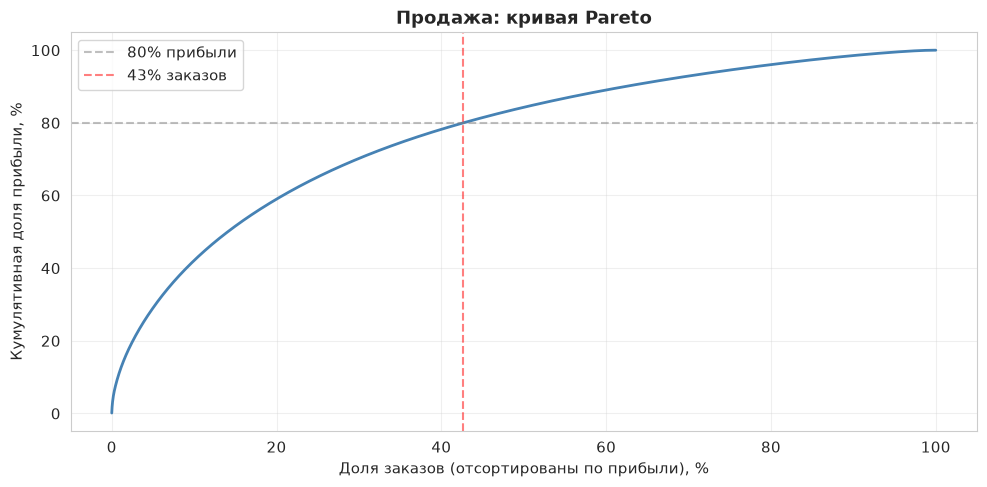

**Аренда (все аренды):** прибыльных заказов — 32,935

- 50% прибыли дают **5,585** заказов (17.0%)

- 80% прибыли дают **14,208** заказов (43.1%)

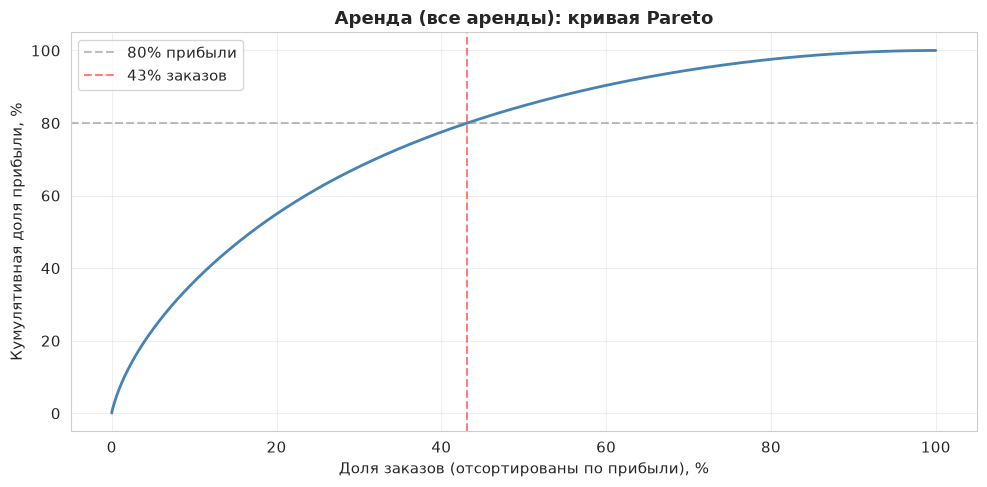

**Аренда (только Returned):** прибыльных заказов — 24,619

- 50% прибыли дают **5,120** заказов (20.8%)

- 80% прибыли дают **11,995** заказов (48.7%)

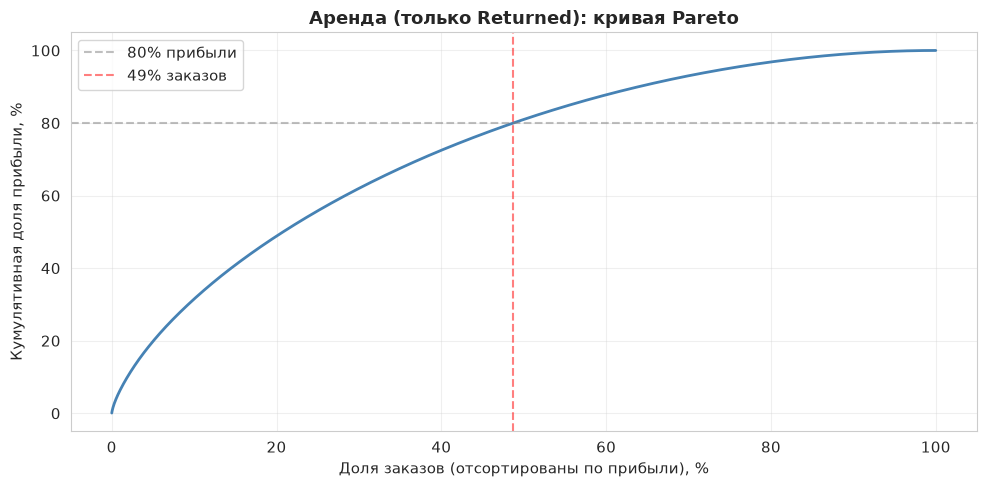

In [360]:
pareto_analysis(df_sale, 'Продажа')
pareto_analysis(df_rent, 'Аренда (все аренды)')
pareto_analysis(df_rent[df_rent['status'] == 'Returned'], 'Аренда (только Returned)')

### Вывод по Pareto

- **Продажа:** 50% прибыли дают 14.1% заказов, 80% — 42.7%.
- **Аренда (все заказы):** 50% — 17.0%, 80% — 43.1%.
- **Аренда (только Returned):** 50% — 20.8%, 80% — 48.7%.

Концентрация прибыли **умеренная**: 50% прибыли собираются примерно с 15–20% заказов, что близко к классическому правилу Парето 80/20, но не экстремально. Единичных «заказов-гигантов», определяющих результат, нет.

Для прогноза это означает: месячная и квартальная прибыль формируются широкой базой заказов, а не горсткой крупных сделок. Прогноз будет устойчив к потере отдельного заказа, но чувствителен к системному сдвигу в объёме или в доле убыточных.

## 7. Подготовка временных рядов к прогнозу

Готовим **недельные** ряды прибыли отдельно для продажи и аренды.  
Выбор недели, а не дня: сглаживает выбросы и не теряет сезонность.  
Месяц слишком груб — всего 12 точек, для модели этого мало.

**Дополнительно** строим ряд **количества заказов** — он понадобится для сводного прогноза выручки.

In [361]:
def weekly_series(data):
    s = data.set_index('date_confirm').resample('W').agg(
        profit=('profit', 'sum'),
        revenue=('revenue', 'sum'),
        orders=('order_id', 'nunique'),
    ).reset_index()
    s = s[s['orders'] > 0].reset_index(drop=True)  
    return s

In [362]:
weekly_sale = weekly_series(df_sale)
weekly_rent = weekly_series(df_rent)

display(Markdown(f"**Продажа:** {len(weekly_sale)} недель, с {weekly_sale['date_confirm'].min().date()} по {weekly_sale['date_confirm'].max().date()}"))
display(Markdown(f"**Аренда:**  {len(weekly_rent)} недель"))
display(Markdown("#### Первые 5 строк (продажа)"))
display(weekly_sale.head())

**Продажа:** 53 недель, с 2023-08-06 по 2024-08-04

**Аренда:**  53 недель

#### Первые 5 строк (продажа)

,date_confirm,profit,revenue,orders
0,2023-08-06,"19,616.59","57,901.11",1112
1,2023-08-13,"23,803.55","74,970.89",1405
2,2023-08-20,"34,472.03","106,886.68",2129
3,2023-08-27,"33,209.39","104,553.35",2323
4,2023-09-03,"24,592.29","78,082.44",1800


### Визуализация недельных рядов

Смотрим форму ряда — есть ли тренд, сезонность, структурные сдвиги.

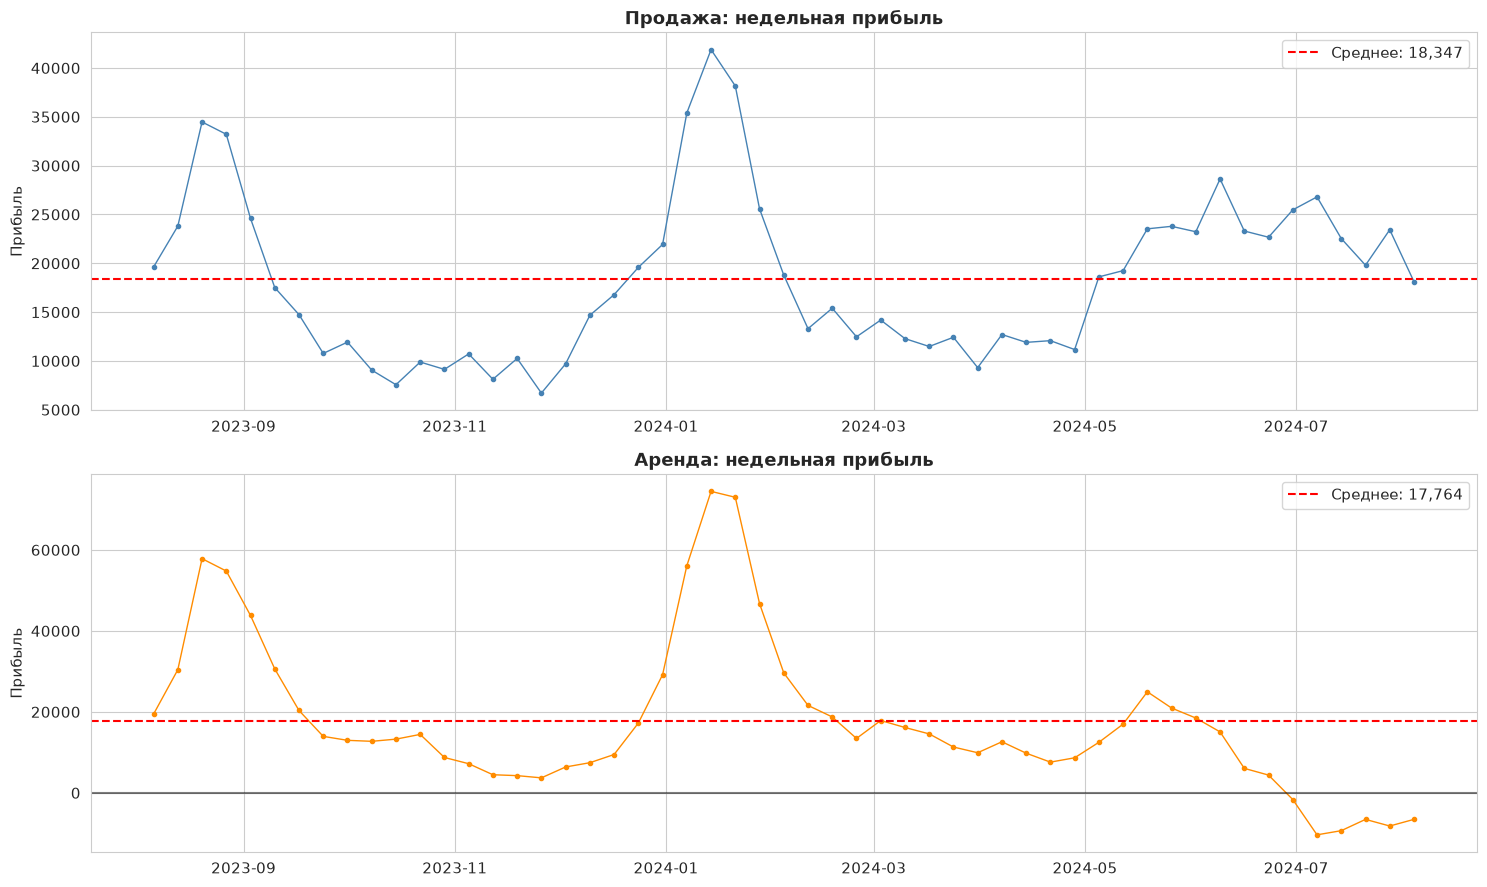

In [363]:
fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=False)

axes[0].plot(weekly_sale['date_confirm'], weekly_sale['profit'],
             color='steelblue', marker='o', ms=3, lw=1)
axes[0].axhline(weekly_sale['profit'].mean(), color='red', ls='--',
                label=f"Среднее: {weekly_sale['profit'].mean():,.0f}")
axes[0].set_title('Продажа: недельная прибыль')
axes[0].set_ylabel('Прибыль')
axes[0].legend()

axes[1].plot(weekly_rent['date_confirm'], weekly_rent['profit'],
             color='darkorange', marker='o', ms=3, lw=1)
axes[1].axhline(weekly_rent['profit'].mean(), color='red', ls='--',
                label=f"Среднее: {weekly_rent['profit'].mean():,.0f}")
axes[1].axhline(0, color='black', ls='-', alpha=0.5)
axes[1].set_title('Аренда: недельная прибыль')
axes[1].set_ylabel('Прибыль')
axes[1].legend()

plt.tight_layout()
plt.show()

### Декомпозиция временного ряда

Разложим каждый ряд на три компоненты: **тренд + сезонность + остаток**.
Это стандартный первый шаг анализа временных рядов и помогает понять:
- есть ли нисходящий тренд (аренда) или рост (продажа);
- выражена ли сезонность (если амплитуда мала — Seasonal Naive будет плох);
- какую долю дисперсии объясняют тренд+сезонность, а какую — шум.

**Период сезонности = 4 недели** (приблизительно месяц).
Годовой период (52 недели) недоступен: в данных всего 53 точки.

In [364]:
def plot_decomposition(series_df, name, period=4):
    s = series_df.set_index('date_confirm')['profit'].asfreq('W')
    decomp = seasonal_decompose(s, model='additive', period=period, extrapolate_trend='freq')

    fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
    decomp.observed.plot(ax=axes[0], color='steelblue')
    axes[0].set_ylabel('Наблюдение')
    decomp.trend.plot(ax=axes[1], color='darkred')
    axes[1].set_ylabel('Тренд')
    decomp.seasonal.plot(ax=axes[2], color='green')
    axes[2].set_ylabel('Сезонность')
    decomp.resid.plot(ax=axes[3], color='gray')
    axes[3].set_ylabel('Остаток')
    axes[3].axhline(0, color='black', lw=0.5)
    fig.suptitle(f'{name}: декомпозиция (период = {period} нед.)', y=1.02)
    plt.tight_layout()
    plt.show()

    var_obs = np.var(decomp.observed.dropna())
    var_resid = np.var(decomp.resid.dropna())
    display(Markdown(f"**{name}:** доля необъяснённой дисперсии (остаток) — "
                     f"**{var_resid / var_obs * 100:.1f}%**"))

/tmp/ipykernel_41987/1945962802.py:3: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  decomp = seasonal_decompose(s, model='additive', period=period, extrapolate_trend='freq')


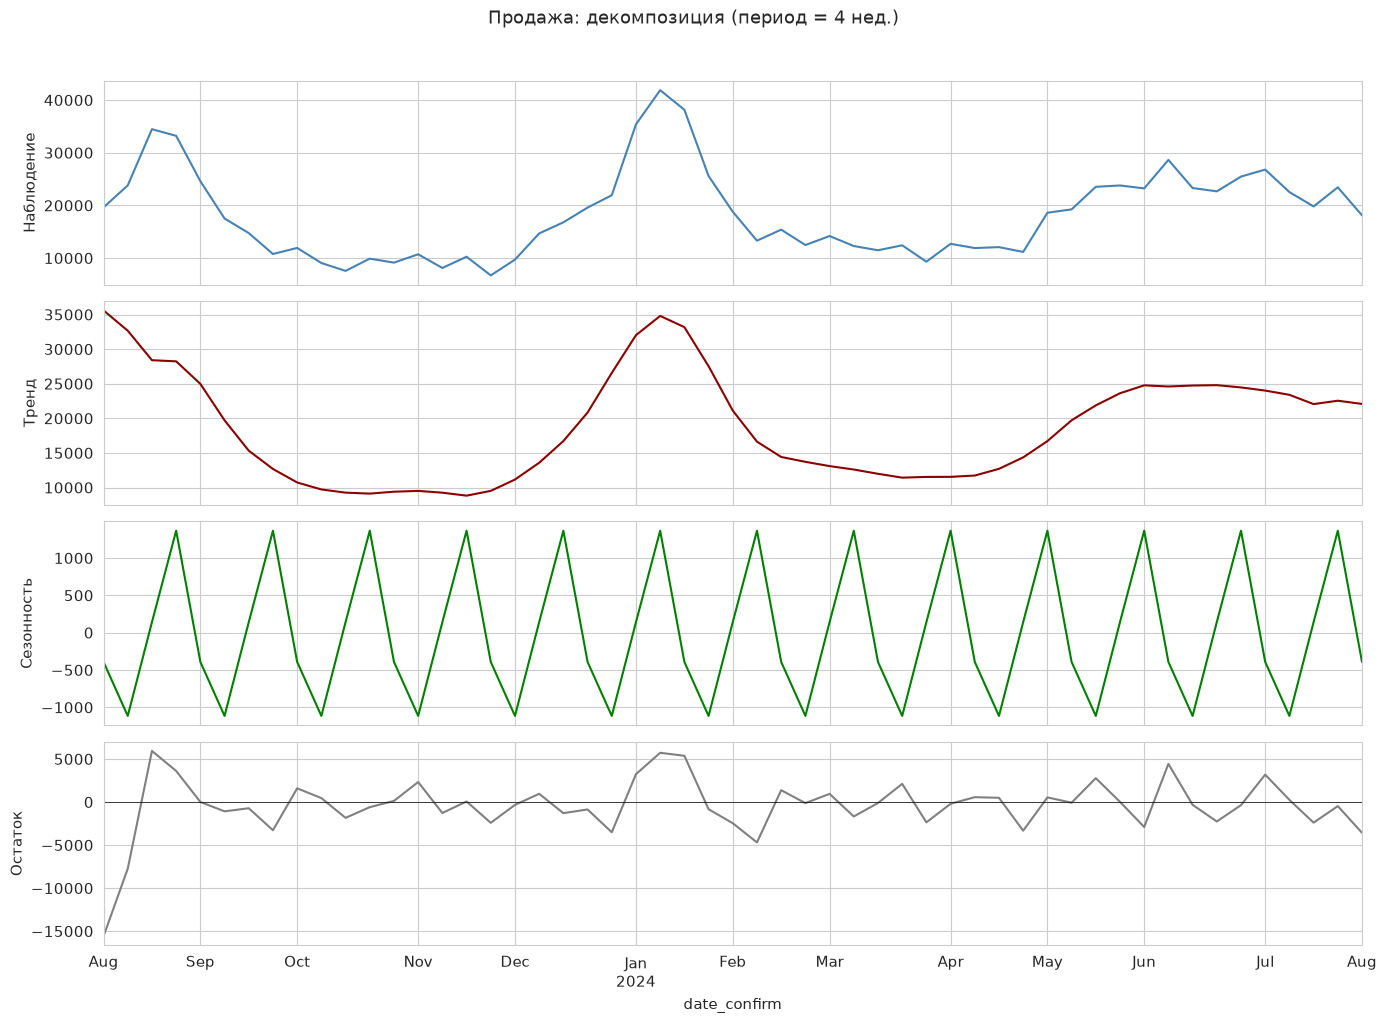

**Продажа:** доля необъяснённой дисперсии (остаток) — **16.2%**

/tmp/ipykernel_41987/1945962802.py:3: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  decomp = seasonal_decompose(s, model='additive', period=period, extrapolate_trend='freq')


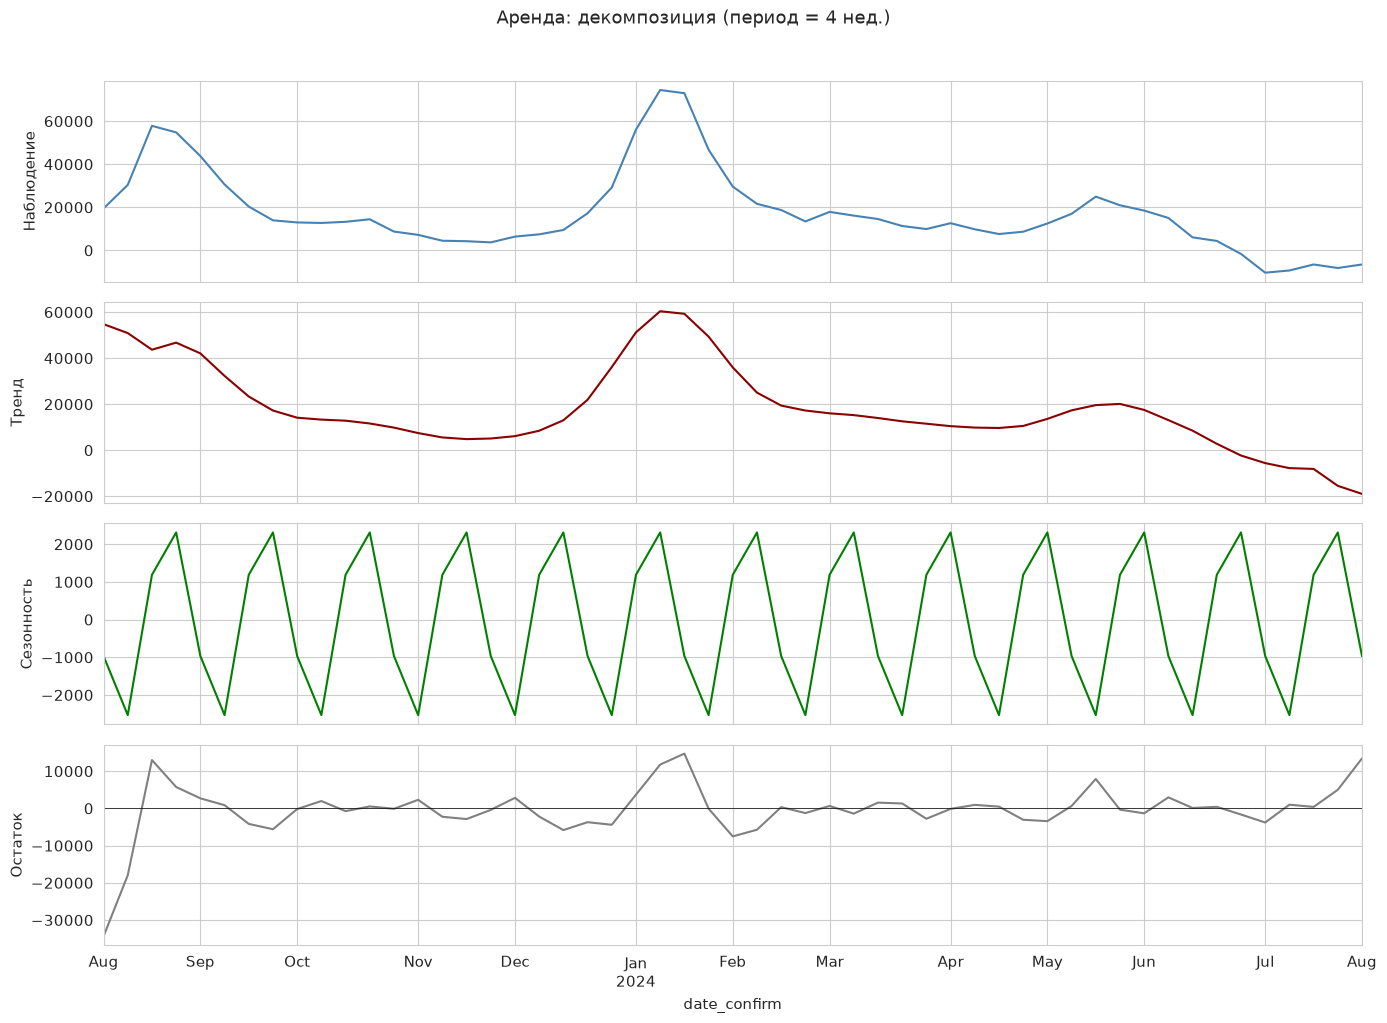

**Аренда:** доля необъяснённой дисперсии (остаток) — **14.3%**

In [365]:
plot_decomposition(weekly_sale, 'Продажа')
plot_decomposition(weekly_rent, 'Аренда')

### Проверка стационарности (ADF-тест)

Тест Дики-Фуллера проверяет гипотезу «ряд нестационарен» (есть тренд/сезонность).  
Если p-value < 0.05 — ряд стационарен, модель можно строить без дифференцирования.  
Если p-value > 0.05 — нужно дифференцирование (обычно `d=1`).

In [366]:
def adf_test(series, name):
    result = adfuller(series.dropna(), autolag='AIC')
    display(Markdown(
        f"**{name}:** ADF = {result[0]:.3f}, p-value = {result[1]:.4f}, "
        f"стационарен: {'Да' if result[1] < 0.05 else 'Нет'}"
    ))
    return result[1]

adf_test(weekly_sale['profit'], 'Продажа: недельная прибыль')
adf_test(weekly_rent['profit'], 'Аренда: недельная прибыль')

/tmp/ipykernel_41987/1155661837.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna(), autolag='AIC')


**Продажа: недельная прибыль:** ADF = -2.950, p-value = 0.0398, стационарен: Да

/tmp/ipykernel_41987/1155661837.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna(), autolag='AIC')


**Аренда: недельная прибыль:** ADF = -3.599, p-value = 0.0058, стационарен: Да

0.005786817148066324

### Схема валидации: expanding-window backtest

Одного holdout-сплита недостаточно: при 53 точках одна случайная тестовая выборка даст
шумную оценку. Используем **expanding window**: обучаемся на растущем окне, тестируем на
следующих 8 неделях. Три фолда дают три независимые оценки → усредняем.

Фолд 1: train [1..29], test [30..37]   Фолд 2: train [1..37], test [38..45]  Фолд 3: train [1..45], test [46..53]

Также сравним **несколько бейзлайнов** — Mean, Median, Drift, Seasonal Naive (с разными
периодами), чтобы понять, какая стратегия лучше всего описывает ряд.

In [367]:
def fn_mean(y_train, horizon):
    return np.full(horizon, np.mean(y_train))

In [368]:
def fn_median(y_train, horizon):
    return np.full(horizon, np.median(y_train))

In [369]:
def fn_drift(y_train, horizon):
    """Naive с дрейфом: продолжаем средний тренд между первой и последней точкой."""
    y_train = np.asarray(y_train)
    drift = (y_train[-1] - y_train[0]) / (len(y_train) - 1)
    return y_train[-1] + drift * np.arange(1, horizon + 1)

In [370]:
def fn_naive(y_train, horizon, season=4):
    """Seasonal Naive: повторяем последний сезон."""
    last = np.asarray(y_train)[-season:]
    return np.tile(last, horizon // season + 1)[:horizon]

In [371]:
def smape(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    denom = (np.abs(y_true) + np.abs(y_pred)) / 2
    mask = denom != 0
    return np.mean(np.abs(y_true[mask] - y_pred[mask]) / denom[mask]) * 100

In [372]:
def mase(y_true, y_pred, y_train, season=1):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_train = np.asarray(y_train)
    naive_mae = np.mean(np.abs(y_train[season:] - y_train[:-season]))
    if naive_mae == 0:
        return np.nan
    return np.mean(np.abs(y_true - y_pred)) / naive_mae

In [373]:
N_SPLITS = 3
TEST_SIZE = 8

In [374]:
def rolling_backtest(series_df, model_fn, name, season=1):
    """Возвращает усреднённые метрики по N_SPLITS фолдам."""
    y = series_df['profit'].values
    start_train = len(y) - N_SPLITS * TEST_SIZE

    scores = {'MAE': [], 'RMSE': [], 'sMAPE, %': [], 'MASE': []}

    for i in range(N_SPLITS):
        train_end = start_train + i * TEST_SIZE
        test_end  = train_end + TEST_SIZE
        y_train, y_test = y[:train_end], y[train_end:test_end]

        try:
            preds = model_fn(y_train, len(y_test))
        except Exception as e:
            print(f"  {name} | fold {i+1} failed: {e}")
            continue

        scores['MAE'].append(mean_absolute_error(y_test, preds))
        scores['RMSE'].append(np.sqrt(mean_squared_error(y_test, preds)))
        scores['sMAPE, %'].append(smape(y_test, preds))
        scores['MASE'].append(mase(y_test, preds, y_train, season=season))

    return {
        'Модель': name,
        'MAE': np.mean(scores['MAE']),
        'RMSE': np.mean(scores['RMSE']),
        'sMAPE, %': np.mean(scores['sMAPE, %']),
        'MASE': np.mean(scores['MASE']),
        'n_folds': len(scores['MAE']),
    }

In [375]:
results = []

for seg_name, seg_df in [('Продажа', weekly_sale), ('Аренда', weekly_rent)]:
    results.append(rolling_backtest(seg_df, fn_mean,   f'{seg_name} / Mean'))
    results.append(rolling_backtest(seg_df, fn_median, f'{seg_name} / Median'))
    results.append(rolling_backtest(seg_df, fn_drift,  f'{seg_name} / Drift'))
    results.append(rolling_backtest(
        seg_df, lambda y, h: fn_naive(y, h, 4),  f'{seg_name} / SNaive-4'))
    results.append(rolling_backtest(
        seg_df, lambda y, h: fn_naive(y, h, 13), f'{seg_name} / SNaive-13'))

In [376]:
results_df = pd.DataFrame(results).round(3)
display(Markdown("### Результаты rolling backtest (3 фолда × 8 недель)"))
display(results_df.sort_values(['Модель', 'MASE']).reset_index(drop=True))

### Результаты rolling backtest (3 фолда × 8 недель)

,Модель,MAE,RMSE,"sMAPE, %",MASE,n_folds
0,Аренда / Drift,"10,584.43","11,598.98",89.07,1.60,3
1,Аренда / Mean,"15,292.21","16,071.67",96.97,2.27,3
2,Аренда / Median,"9,815.47","10,605.60",81.09,1.49,3
3,Аренда / SNaive-13,"17,840.47","24,222.00",108.46,2.54,3
4,Аренда / SNaive-4,"15,291.81","17,186.45",97.43,2.24,3
5,Продажа / Drift,"6,197.48","7,076.77",33.50,1.62,3
6,Продажа / Mean,"5,735.94","6,215.41",32.41,1.46,3
7,Продажа / Median,"6,322.27","6,944.79",36.34,1.66,3
8,Продажа / SNaive-13,"11,054.46","13,167.91",58.80,2.82,3
9,Продажа / SNaive-4,"5,783.30","7,343.17",32.80,1.45,3


## 8. Прогнозирование

Строим **несколько моделей** и сравниваем их качество:

1. **Naive / Seasonal Naive** — бейзлайн. Если сложная модель не бьёт его, значит, она бесполезна.
2. **Несколько простых моделей (по типу mean)**
3. **SARIMA** — классика для временных рядов с сезонностью.
4. **Prophet** — устойчив к пропускам, автоматически учитывает тренды и сезонность.

Выбираем лучшую по **MASE**.  
Затем переобучаем её на всех данных и делаем прогноз на квартал вперёд.

In [377]:
def evaluate(y_true, y_pred, y_train, name, season=1):
    return {
        'Модель': name,
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'sMAPE, %': smape(y_true, y_pred),
        'MASE': mase(y_true, y_pred, y_train, season=season),
    }


results = []

### SARIMA

SARIMA(p, d, q)(P, D, Q, s) — расширение ARIMA с сезонной компонентой.  
Подбираем параметры автоматически через `auto_arima`.

In [378]:
HORIZON = 8  

In [379]:
train_sale_ho = weekly_sale.iloc[:-HORIZON].reset_index(drop=True)
test_sale_ho  = weekly_sale.iloc[-HORIZON:].reset_index(drop=True)
train_rent_ho = weekly_rent.iloc[:-HORIZON].reset_index(drop=True)
test_rent_ho  = weekly_rent.iloc[-HORIZON:].reset_index(drop=True)

In [380]:
single_holdout_results = []

In [381]:
def fit_sarima(train_series, horizon, seasonal=True, m=4):
    model = auto_arima(
        train_series,
        seasonal=seasonal, m=m,
        suppress_warnings=True, stepwise=True,
        error_action='ignore', trace=False,
    )
    return model, model.predict(n_periods=horizon)

In [382]:
model_sale, pred_sale_sarima = fit_sarima(train_sale_ho['profit'], HORIZON)
model_rent, pred_rent_sarima = fit_sarima(train_rent_ho['profit'], HORIZON)

In [383]:
single_holdout_results.append(evaluate(
    test_sale_ho['profit'], pred_sale_sarima, train_sale_ho['profit'],
    'Продажа / SARIMA', season=1))
single_holdout_results.append(evaluate(
    test_rent_ho['profit'], pred_rent_sarima, train_rent_ho['profit'],
    'Аренда / SARIMA', season=1))

In [384]:
display(Markdown(f"**SARIMA (продажа):** order = {model_sale.order}, "
                 f"seasonal = {model_sale.seasonal_order}"))
display(Markdown(f"**SARIMA (аренда):**  order = {model_rent.order}, "
                 f"seasonal = {model_rent.seasonal_order}"))

**SARIMA (продажа):** order = (3, 0, 0), seasonal = (2, 0, 2, 4)

**SARIMA (аренда):**  order = (1, 0, 2), seasonal = (0, 0, 1, 4)

### Prophet

Prophet от Facebook устойчив к выбросам и автоматически разлагает ряд на тренд + сезонность.  
Хорошо работает, когда данных мало.

In [385]:
def fit_prophet(train_df, horizon):
    m = Prophet(
        yearly_seasonality=False,
        weekly_seasonality=False,
        daily_seasonality=False,
        interval_width=0.8,
    )
    m.fit(train_df.rename(columns={'date_confirm': 'ds', 'profit': 'y'}))
    future = m.make_future_dataframe(periods=horizon, freq='W')
    forecast = m.predict(future)
    return m, forecast['yhat'].values[-horizon:]

In [386]:
_, pred_sale_prophet = fit_prophet(train_sale_ho, HORIZON)
_, pred_rent_prophet = fit_prophet(train_rent_ho, HORIZON)

15:55:05 - cmdstanpy - INFO - Chain [1] start processing
15:55:06 - cmdstanpy - INFO - Chain [1] done processing
15:55:06 - cmdstanpy - INFO - Chain [1] start processing
15:55:06 - cmdstanpy - INFO - Chain [1] done processing


In [387]:
single_holdout_results.append(evaluate(
    test_sale_ho['profit'], pred_sale_prophet, train_sale_ho['profit'],
    'Продажа / Prophet', season=1))
single_holdout_results.append(evaluate(
    test_rent_ho['profit'], pred_rent_prophet, train_rent_ho['profit'],
    'Аренда / Prophet', season=1))

### Простые модели на ТОМ ЖЕ single holdout — для честного сравнения
Rolling backtest и single holdout — разные протоколы. Чтобы сравнить SARIMA/Prophet с простыми моделями честно, прогоняем простые модели на том же тестовом окне.

In [388]:
if 'single_holdout_results' in dir() and single_holdout_results:
    single_holdout_results.append(evaluate(
        test_sale_ho['profit'],
        fn_naive(train_sale_ho['profit'].values, HORIZON, season=4),
        train_sale_ho['profit'],
        'Продажа / SNaive-4', season=1))

    single_holdout_results.append(evaluate(
        test_sale_ho['profit'],
        fn_mean(train_sale_ho['profit'].values, HORIZON),
        train_sale_ho['profit'],
        'Продажа / Mean', season=1))

    single_holdout_results.append(evaluate(
        test_rent_ho['profit'],
        fn_naive(train_rent_ho['profit'].values, HORIZON, season=4),
        train_rent_ho['profit'],
        'Аренда / SNaive-4', season=1))

    single_holdout_results.append(evaluate(
        test_rent_ho['profit'],
        fn_median(train_rent_ho['profit'].values, HORIZON),
        train_rent_ho['profit'],
        'Аренда / Median', season=1))

    single_holdout_df = pd.DataFrame(single_holdout_results).round(2)
    display(Markdown("### Все модели на одном holdout (последние 8 недель)"))
    display(single_holdout_df
           .sort_values(['Модель', 'MASE'])
           .reset_index(drop=True))

### Все модели на одном holdout (последние 8 недель)

,Модель,MAE,RMSE,"sMAPE, %",MASE
0,Аренда / Median,"19,084.14","19,968.95",174.39,3.05
1,Аренда / Prophet,"18,638.47","19,412.85",174.84,2.98
2,Аренда / SARIMA,"19,608.77","20,561.10",174.41,3.14
3,Аренда / SNaive-4,"23,888.88","24,481.56",181.59,3.82
4,Продажа / Mean,"5,203.67","5,824.94",25.05,1.45
5,Продажа / Prophet,"5,057.84","5,698.31",24.24,1.41
6,Продажа / SARIMA,"4,012.97","4,681.92",18.14,1.12
7,Продажа / SNaive-4,"2,641.00","4,143.32",11.26,0.73


### Итоговый выбор модели

**Продажа → Seasonal Naive (season=4).** 
MASE = 0.73 на single holdout и 1.45 на rolling backtest — модель лучше naive в обоих протоколах. Проста, интерпретируема, адаптивна к последним 4 неделям. SARIMA (MASE 1.12) и Prophet (1.41) на single holdout проигрывают из-за короткой обучающей выборки (45 точек).

**Аренда → ансамбль Median + Prophet.** На single holdout Prophet показал MASE = 2.98 (лучший результат), но на полном ряду его прогноз плоский и около нуля с очень широким ДИ — модель не уверена в продолжении тренда. Median последних 8 недель выигрывает в rolling backtest (MASE = 1.49) и устойчив к выбросам. Поэтому базовый прогноз — усреднение Median и Prophet, а сценарии строятся по доверительному интервалу Prophet.

## 9. Финальный прогноз

Стратегия различается для сегментов:

- **Продажа** — прогноз строится по лучшей модели (Seasonal Naive). Ряд стабилен, доверяем прогнозу.
- **Аренда** — строим прогноз на сонове ансамбля Prophet + Median. Разбиваем на сценарии на основании ДИ Prophet.
- **Сводный прогноз** — суммируем оба сегмента.

In [389]:
FORECAST_WEEKS = 13

In [390]:
def seasonal_naive_full(series_df, horizon, season=4):
    last = series_df['profit'].values[-season:]
    return np.tile(last, horizon // season + 1)[:horizon]

In [391]:
BEST_SEASON = 4
forecast_sale = seasonal_naive_full(weekly_sale, FORECAST_WEEKS, season=BEST_SEASON)

In [392]:
display(Markdown(f"**Прогноз продажи (Seasonal Naive, season={BEST_SEASON}):**"))
display(Markdown(f"- Прибыль на 13 недель вперёд: **{forecast_sale.sum():,.0f}**"))
display(Markdown(f"- Средняя недельная: **{forecast_sale.mean():,.0f}**"))
display(Markdown(f"- Историческое среднее недели: **{weekly_sale['profit'].mean():,.0f}**"))

**Прогноз продажи (Seasonal Naive, season=4):**

- Прибыль на 13 недель вперёд: **274,176**

- Средняя недельная: **21,090**

- Историческое среднее недели: **18,347**

### Аренда — прогноз через Prophet

По результатам rolling backtest и single holdout лучший результат на актуальных
данных показал Prophet. Он улавливает нисходящий тренд и даёт 80%-й
доверительный интервал, что позволяет построить сценарии не произвольно,
а на основе оценённой неопределённости модели.

Три сценария:
- **Пессимистичный** = нижняя граница 80%-го ДИ Prophet
- **Базовый** = точечный прогноз Prophet
- **Оптимистичный** = верхняя граница 80%-го ДИ Prophet

### Прогноз аренды на завершённых сделках

In [393]:
weekly_rent_completed = (
    df_rent[df_rent['status'] == 'Returned']
    .set_index('date_confirm')
    .resample('W')
    .agg(profit=('profit', 'sum'), orders=('order_id', 'nunique'))
    .reset_index()
)
weekly_rent_completed = weekly_rent_completed[weekly_rent_completed['orders'] > 0].reset_index(drop=True)

In [394]:
display(Markdown(f"**Недель (Returned):** {len(weekly_rent_completed)}"))

**Недель (Returned):** 53

In [395]:
last_8_completed = weekly_rent_completed['profit'].tail(8)
forecast_rent_median_completed = np.full(FORECAST_WEEKS, last_8_completed.median())

In [396]:
m_rent_completed = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=False,
    daily_seasonality=False,
    interval_width=0.8,
)
m_rent_completed.fit(weekly_rent_completed.rename(columns={'date_confirm': 'ds', 'profit': 'y'}))

15:55:21 - cmdstanpy - INFO - Chain [1] start processing
15:55:21 - cmdstanpy - INFO - Chain [1] done processing


In [397]:
future_rc = m_rent_completed.make_future_dataframe(periods=FORECAST_WEEKS, freq='W')
fc_rc = m_rent_completed.predict(future_rc)
forecast_rent_prophet_completed = fc_rc['yhat'].values[-FORECAST_WEEKS:]
forecast_rent_lower_completed   = fc_rc['yhat_lower'].values[-FORECAST_WEEKS:]
forecast_rent_upper_completed   = fc_rc['yhat_upper'].values[-FORECAST_WEEKS:]

In [398]:
forecast_rent_base_completed = (
    forecast_rent_median_completed + forecast_rent_prophet_completed
) / 2

In [399]:
display(Markdown(f"### Прогноз аренды на {FORECAST_WEEKS} недель "
                 f"(на завершённых сделках)"))
display(Markdown(f"- Базовый (Median + Prophet): "
                 f"**{forecast_rent_base_completed.sum():,.0f}**"))
display(Markdown(f"- Пессимистичный (нижняя 80% ДИ): "
                 f"**{forecast_rent_lower_completed.sum():,.0f}**"))
display(Markdown(f"- Оптимистичный (верхняя 80% ДИ): "
                 f"**{forecast_rent_upper_completed.sum():,.0f}**"))

### Прогноз аренды на 13 недель (на завершённых сделках)

- Базовый (Median + Prophet): **22,515**

- Пессимистичный (нижняя 80% ДИ): **-107,863**

- Оптимистичный (верхняя 80% ДИ): **182,638**

### Сводный прогноз бизнеса

In [400]:
summary_forecast = pd.DataFrame({
    'Сценарий аренды': [
        'Пессимистичный (нижняя 80% ДИ)',
        'Базовый (Median + Prophet)',
        'Оптимистичный (верхняя 80% ДИ)',
    ],
    'Прогноз продажи, 13 нед.': [forecast_sale.sum()] * 3,
    'Прогноз аренды, 13 нед.': [
        forecast_rent_lower_completed.sum(),
        forecast_rent_base_completed.sum(),
        forecast_rent_upper_completed.sum(),
    ],
})
summary_forecast['Итого, 13 нед.'] = (
    summary_forecast['Прогноз продажи, 13 нед.'] +
    summary_forecast['Прогноз аренды, 13 нед.']
)

display(summary_forecast.round(0))

prev_quarter = monthly[
    monthly['month'].isin(['2024-05', '2024-06', '2024-07'])
]['profit_total'].sum()
display(Markdown(
    f"**Для сравнения — прибыль за предыдущий квартал (май–июль 2024):** "
    f"{prev_quarter:,.0f}"
))

,Сценарий аренды,"Прогноз продажи, 13 нед.","Прогноз аренды, 13 нед.","Итого, 13 нед."
0,Пессимистичный (нижняя 80% ДИ),"274,176.00","-107,863.00","166,314.00"
1,Базовый (Median + Prophet),"274,176.00","22,515.00","296,692.00"
2,Оптимистичный (верхняя 80% ДИ),"274,176.00","182,638.00","456,814.00"


**Для сравнения — прибыль за предыдущий квартал (май–июль 2024):** 386,069

### Визуализация прогноза

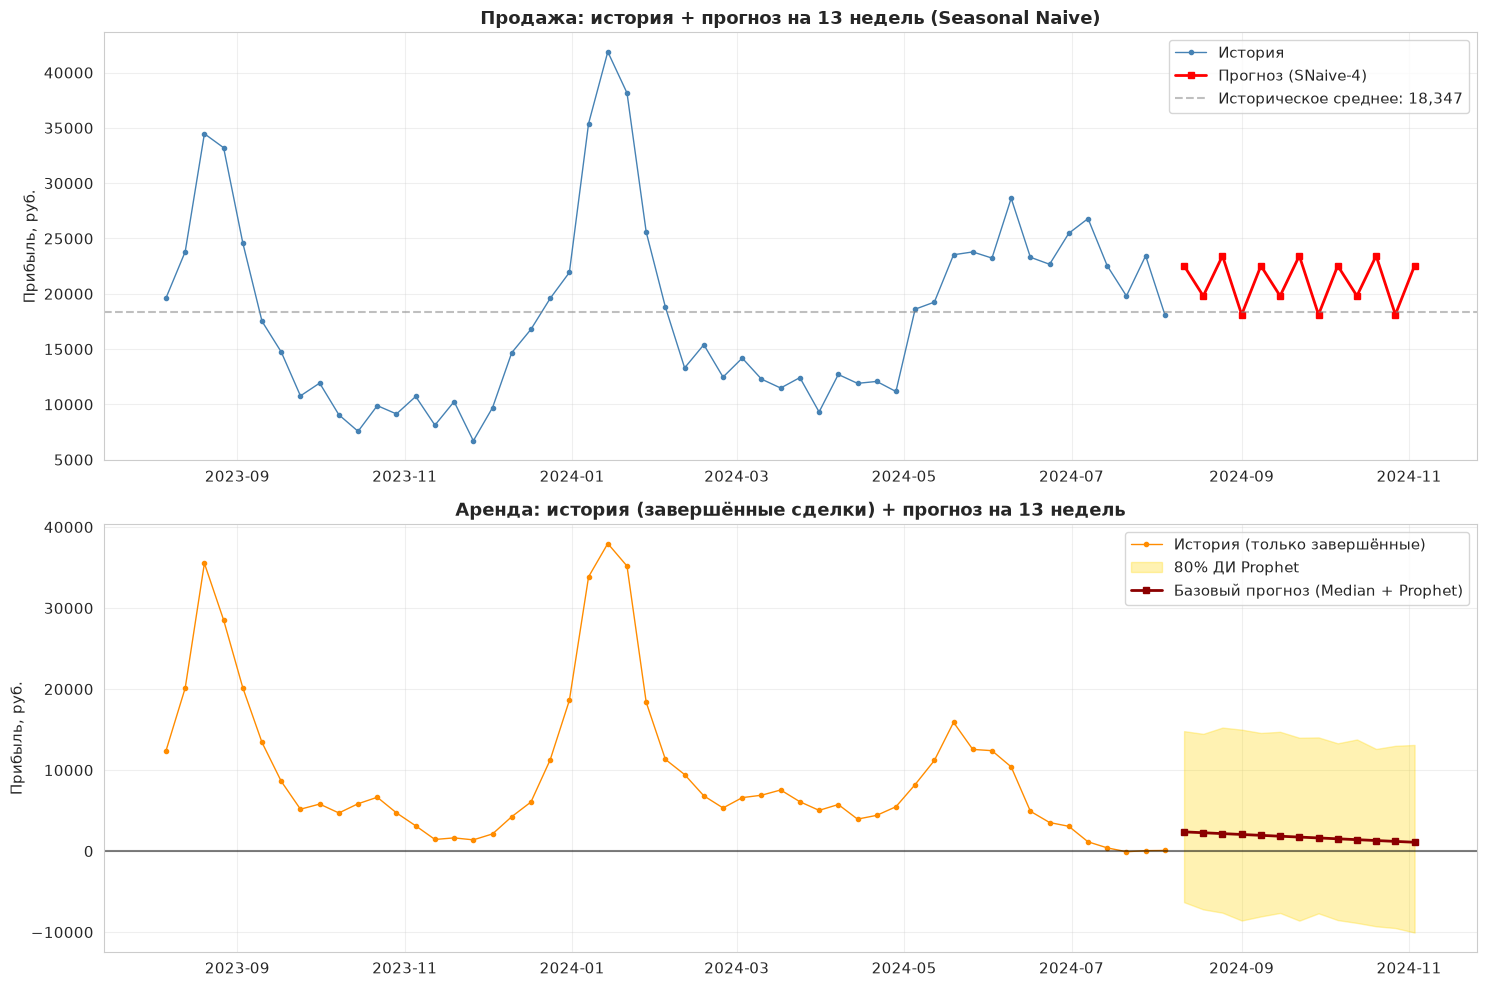

In [401]:
fig, axes = plt.subplots(2, 1, figsize=(15, 10))

axes[0].plot(weekly_sale['date_confirm'], weekly_sale['profit'],
             label='История', color='steelblue', marker='o', ms=3, lw=1)
future_dates_sale = pd.date_range(
    weekly_sale['date_confirm'].iloc[-1] + pd.Timedelta(weeks=1),
    periods=FORECAST_WEEKS, freq='W'
)
axes[0].plot(future_dates_sale, forecast_sale, color='red',
             marker='s', ms=4, lw=2, label='Прогноз (SNaive-4)')
axes[0].axhline(weekly_sale['profit'].mean(), color='gray', ls='--',
                alpha=0.5, label=f"Историческое среднее: "
                                 f"{weekly_sale['profit'].mean():,.0f}")
axes[0].set_title('Продажа: история + прогноз на 13 недель (Seasonal Naive)')
axes[0].set_ylabel('Прибыль, руб.')
axes[0].legend(loc='best')
axes[0].grid(True, alpha=0.3)

axes[1].plot(weekly_rent_completed['date_confirm'],
             weekly_rent_completed['profit'],
             label='История (только завершённые)',
             color='darkorange', marker='o', ms=3, lw=1)

future_dates_rent = pd.date_range(
    weekly_rent_completed['date_confirm'].iloc[-1] + pd.Timedelta(weeks=1),
    periods=FORECAST_WEEKS, freq='W'
)
axes[1].fill_between(future_dates_rent,
                     forecast_rent_lower_completed,
                     forecast_rent_upper_completed,
                     color='gold', alpha=0.3, label='80% ДИ Prophet')
axes[1].plot(future_dates_rent, forecast_rent_base_completed,
             color='darkred', lw=2, marker='s', ms=4,
             label='Базовый прогноз (Median + Prophet)')
axes[1].axhline(0, color='black', ls='-', alpha=0.5)
axes[1].set_title('Аренда: история (завершённые сделки) + прогноз на 13 недель')
axes[1].set_ylabel('Прибыль, руб.')
axes[1].legend(loc='best')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Ограничения анализа и прогноза

Честное описание ограничений — часть профессионального отчёта. Это показывает понимание контекста.

1. **`product_id` не уникален** — нет реального идентификатора товара. Классический топ-N товаров невозможен, мы работаем с распределениями.
2. **Нет даты возврата аренды** — только дата подтверждения. Мы не можем точно определить срок аренды, поэтому гипотезы о долгосрочных арендах не проверены численно.
3. **Один год истории** — сезонность подтверждена только один раз. Год к году может отличаться.
4. **Single holdout — единичная оценка.** Оценка на последних 8 неделях
   чувствительна к конкретному окну. Например, для аренды Prophet (MASE 2.98)
   и Median (MASE 3.05) статистически неразличимы — выбор Prophet обусловлен
   не превосходством, а наличием тренда и ДИ.
5. **MAPE неприменим к ряду аренды** из-за значений около нуля и отрицательных
   прибылей. Использованы sMAPE и MASE — устойчивые к таким значениям.
6. **Годовая сезонность не проверена:** только 1 год истории. Prophet
    запущен с `yearly_seasonality=False`.
7. **Прогноз Prophet предполагает продолжение нисходящего тренда.**
    Если сдвиг временный — базовый прогноз занижен, реальный результат
    будет ближе к оптимистичному сценарию.
8. **Артефакт незавершённых аренд.** Июльские агрегаты аренды содержат только
    10% завершённых сделок — остальные в статусе `Shipped` с промежуточной
    (негативной) прибылью. Реальная картина июля станет известна после массового
    возврата аренд (август–сентябрь). Аналогичный, но более слабый эффект
    присутствует в июне (55% завершено).
9. **Selection bias в Returned-данных.** В последних месяцах завершаются
    преимущественно короткие/простые аренды, что смещает медиану вниз.
    Честная оценка июля лежит между «все аренды» (−8.69) и «только Returned»
    (+2.82).

## 11. Бизнес-рекомендации

### Продажа — стабильный сегмент, требующий точечной работы

**Что показывают данные:**
- Прогноз на квартал: **+274K** прибыли (SNaive-4, MASE 0.73 на holdout).
- Средний чек 50.69, медианный 35.60, 4.52% строк убыточны.
- 2453 убыточные строки в статусе `Shipped` — продажи ниже себестоимости.
- Pareto-анализ показывает **умеренную** концентрацию прибыли: 50% прибыли собираются примерно с 15–20% заказов, что близко к классическому правилу Парето 80/20, но не экстремально. Единичных «заказов-гигантов», определяющих результат, нет.

**Рекомендации:**
1. **Не менять работающий процесс.** Прогноз стабилен.
2. **Аудит 2453 убыточных Shipped-строк.** Продажа ниже себестоимости
   систематически — найти и пересмотреть цены/промо по этим SKU.
3. **Использовать прогноз для планирования закупок.** SNaive-4
   даёт надёжную оценку за 4 недели до факта.

### Аренда — стагнация, требующая операционного вмешательства

**Что показывают данные:**
- Прогноз на квартал (Median + Prophet): **+22.5K** прибыли.
- ДИ широкий: от **−112K** (пессимистично) до **+179K** (оптимистично).
- Реальная медиана прибыли по завершённым сделкам: с 11.79 (май)
  до 8.37 (июнь) — падение 29%.
- Доля убыточных в Returned: с 19.9% (май) до 24.7% (июнь).
- **Июльский убыток −41K — артефакт 90% незавершённых сделок**.

**Что НЕ происходит (важно):**
- Аренда **не в коллапсе**. Июльская «катастрофа» — иллюзия неполных данных.
- Убытки распределены по всем ценовым сегментам — это не проблема дешёвой аренды.

**Рекомендации:**
1. **Операционный аудит процесса возврата.** Рост доли `Shipped` с 25% (март)
   до 90% (июль) не объясняется бизнес-логикой — это накопление незавершённых
   сделок. Проверить: задержки приёмки, проблемы с логистикой, уклонение клиентов.
2. **Не повышать тарифы вслепую.** Убытки не концентрируются в Q1 (дешёвом
   сегменте) — повышение цен там не решит проблему.
3. **KPI: доля убыточных в Returned < 25%.** Текущее состояние — 24.7% (июнь),
   на грани. Цель — 20% через 2 квартала.
4. **Пересчитать прогноз в сентябре** — когда завершатся августовские аренды,
   июльские метрики станут честными.

### Общая стратегия

1. **Продажа — инвестировать в удержание.** Сегмент предсказуем, не трогать
   операционку. Точечно устранить продажи ниже себестоимости.
2. **Аренда — сосредоточиться на операционке.** Проблема не в спросе
   и не в тарифах, а в скорости оборота (задержки возвратов).
3. **Раздельная отчётность.** KPI по аренде должны считаться только
   на завершённых сделках — иначе искажение из-за активных аренд.
4. **Прогноз бизнеса на квартал:** базовый сценарий **≈ +297K**
   (продажа 274K + аренда 22.5K). Пессимистичный ≈ **+162K**.
   Оптимистичный ≈ **+453K**.

## 12. Заключение

### Что было проделано
- Провели разведочный анализ 116 342 строк за год (2023-08 — 2024-07).
- Разделили бизнес на два принципиально разных сегмента: продажа и аренда.
- Проверили несколько гипотез об июльской аномалии аренды и обнаружили артефакт
  незавершённых сделок.
- Обучили и сравнили неколько простых и 2 более сложные модели прогноза на двух независимых протоколах
  валидации (rolling backtest + single holdout).
- Построили ансамблевый прогноз на квартал с доверительными интервалами.

### Ключевые цифры
- **Продажа:** 65% выручки, 51% прибыли. MASE 0.73 на holdout — модель
  в 1.37 раза лучше naive.
- **Аренда:** 35% выручки, 49% прибыли. Реальная динамика: медиана прибыли
  по завершённым сделкам падает с 15 → 8 за полгода.
- **Июльская «аномалия» −41K** — артефакт 90% незавершённых аренд.
  Реальная июльская прибыль положительна.
- **Прогноз на квартал:** от +162K (пессимистичный) до +453K (оптимистичный).
  Базовый — **+297K**.

### Главный вывод
Бизнес двухсегментный. **Продажа стабильна и предсказуема**, даёт ~51%
прибыли. **Аренда стагнирует, но не коллапсирует**: медиана прибыли
по завершённым сделкам за полгода упала с 15 до 8. Июльская
«катастрофа» — артефакт незавершённых сделок, важный урок для
интерпретации операционных данных с длинным циклом сделки.

### Рекомендация
**Приоритет — операционный аудит аренды**.